In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd

In [ ]:
#funties om te gebruiken
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as

def lineaire_functie(x,a,b):
    return a*x + b
def plot(x_as, y_as, x_label, y_label, title):
    plt.plot(x_as, y_as, )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.show()

def lorentz(x, x0, gamma, A):
    return A * (0.5*gamma)**2 / ((x - x0)**2 + (0.5*gamma)**2)

def multi_lorentz(x, *params):
    # Laatste parameter is de achtergrond
    B = params[-1]
    y_model = np.zeros_like(x) + B

    # Door de overige parameters in stapjes van 3 lopen
    # (x0, gamma, A) per piek
    for i in range(0, len(params) - 1, 3):
        x0 = params[i]
        gamma = params[i + 1]
        A = params[i + 2]
        y_model += lorentz(x, x0, gamma, A)

    return y_model

def subtract(x_foreground, y_foreground, x_background, y_background):
    y_interpolated = np.interp(x_foreground, x_background, y_background)
    y_subtracted = y_foreground - y_interpolated

    return x_foreground, y_subtracted



def load_file(number: int, folder_path) -> pd.DataFrame:

    filename = f"TEK{number:04d}.CSV"
    filepath = os.path.join(folder_path, filename)

    if not os.path.exists(filepath):
        print(f"Bestand niet gevonden: {filename}")
        return None

    df = pd.read_csv(
        filepath,
        header=None,
        usecols=[3, 4],
        names=["time", "voltage"],
        encoding="utf-8"
    )

    # Verwijder rijen waar time of voltage geen getal is (de metadata-rijen)
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

    #print(f"Geladen: {filename} — {len(df)} datapunten")
    x_as = df["time"].values
    y_as = df["voltage"].values
    return x_as, y_as

def file_data(folder_path,N):
    x_subs = []
    y_subs = []
    teller_foreground = 1
    teller_background = 0

    while teller_foreground < N:
        if teller_foreground!=41 or teller_foreground!=80 or teller_foreground != 120 or teller_foreground != 160:
            x_foreground, y_foreground = load_file(teller_foreground, folder_path)
            x_background, y_background = load_file(teller_background, folder_path)

            if x_foreground is None or x_background is None:
                print(f"Fout bij het laden van bestanden: TEK{teller_foreground:04d} of TEK{teller_background:04d}")
                continue
            #subtration:
            x_subtracted, y_subtracted = subtract(x_foreground, y_foreground, x_background, y_background)
            x_subs.append(x_subtracted)
            y_subs.append(y_subtracted) 
            plt.plot(x_subtracted, y_subtracted)
            plt.xlabel("Time (s)")
            plt.ylabel("Voltage (V)")
            plt.title(f"Voltage vs Time - TEK{teller_foreground:04d} - TEK{teller_background:04d}, subtracted")
            plt.show()
        teller_foreground += 2
        teller_background += 2
    return x_subs, y_subs


1
0


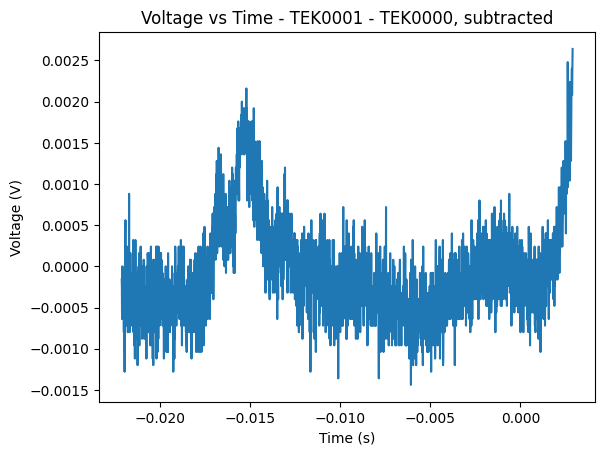

3
2


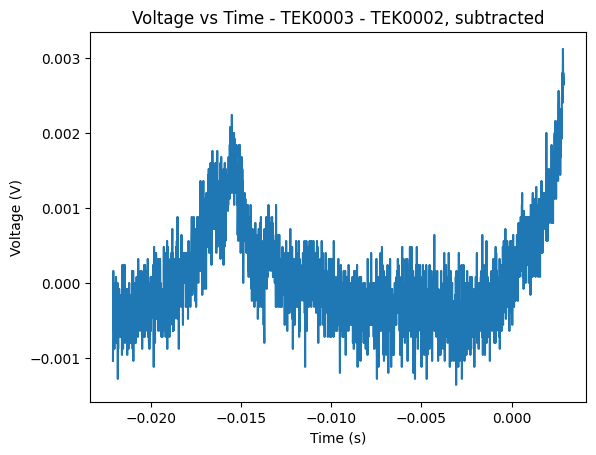

5
4


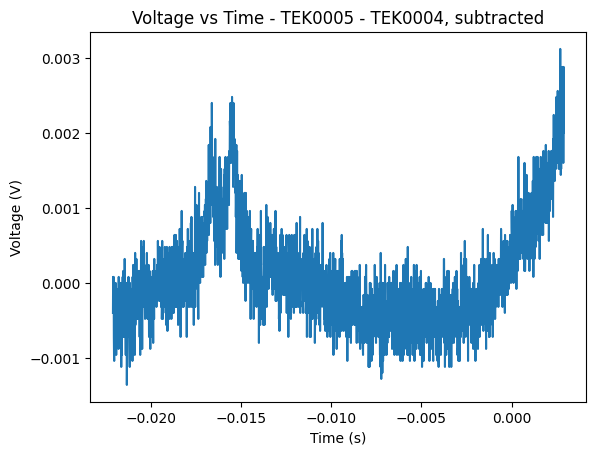

7
6


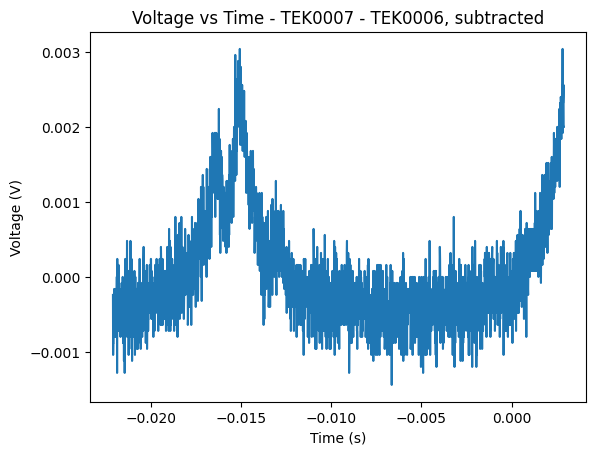

9
8


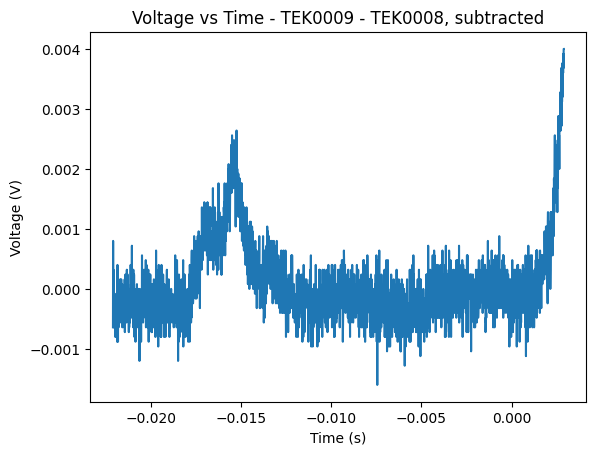

11
10


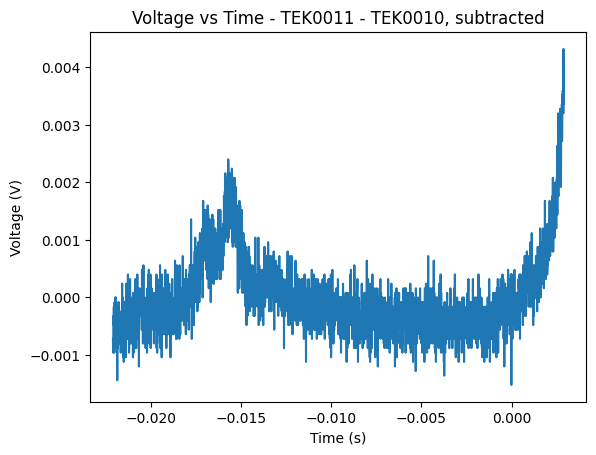

13
12


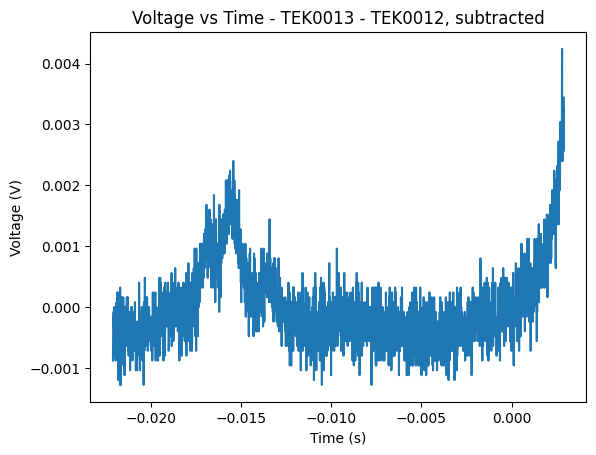

15
14


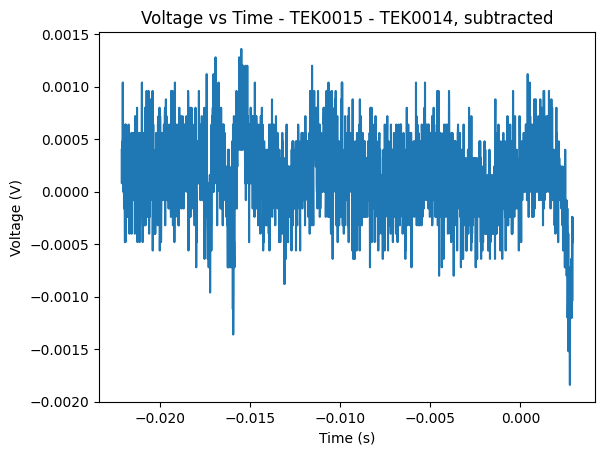

17
16


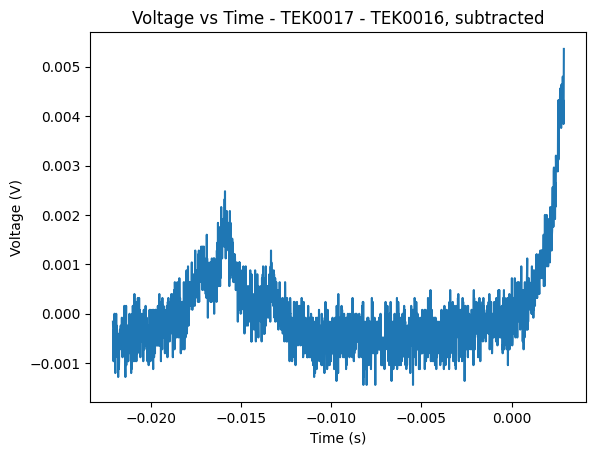

19
18


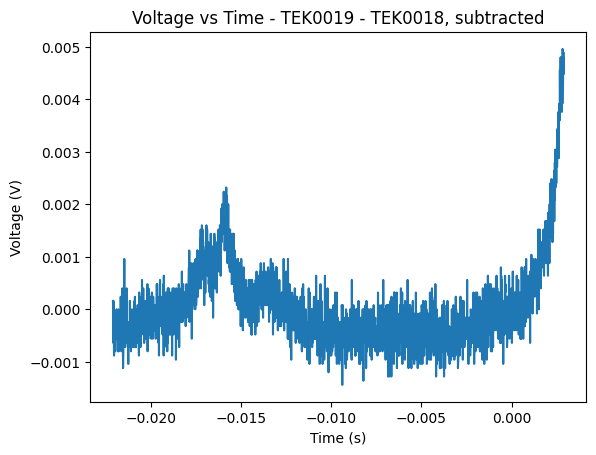

21
20


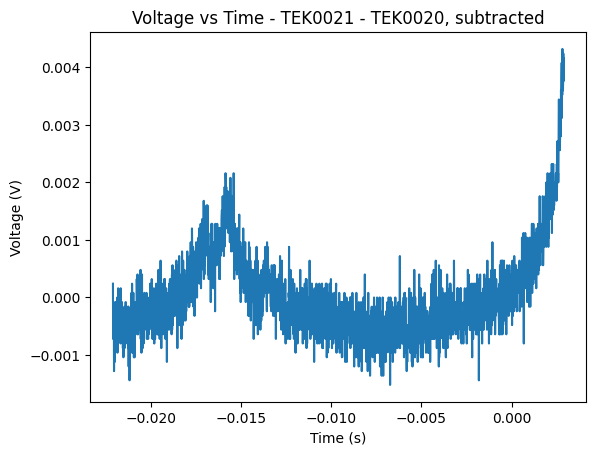

23
22


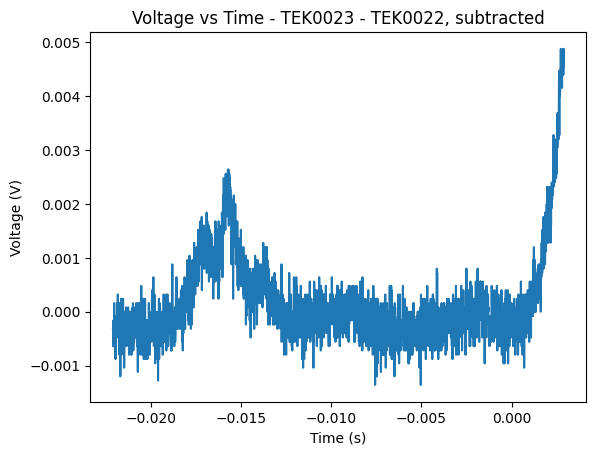

25
24


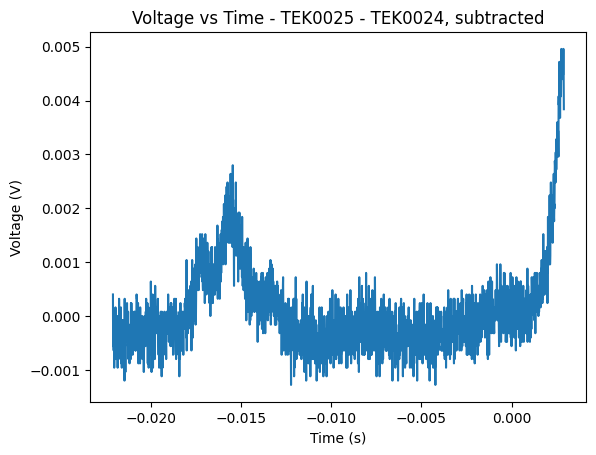

27
26


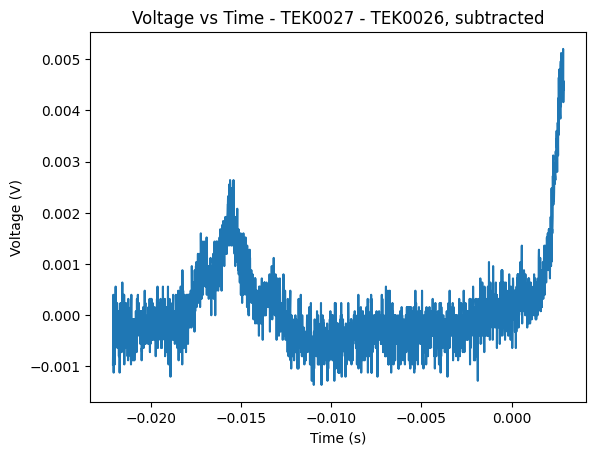

29
28


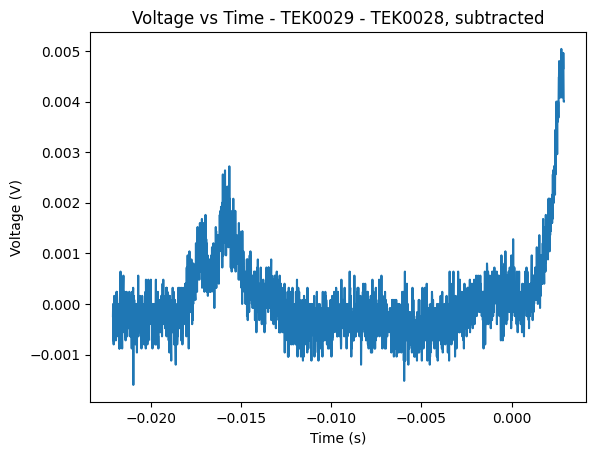

31
30


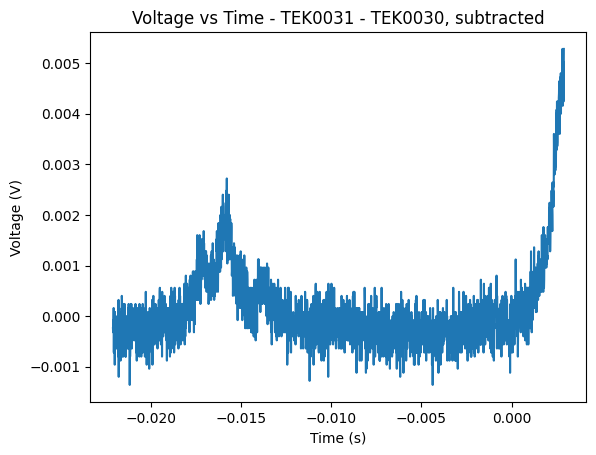

33
32


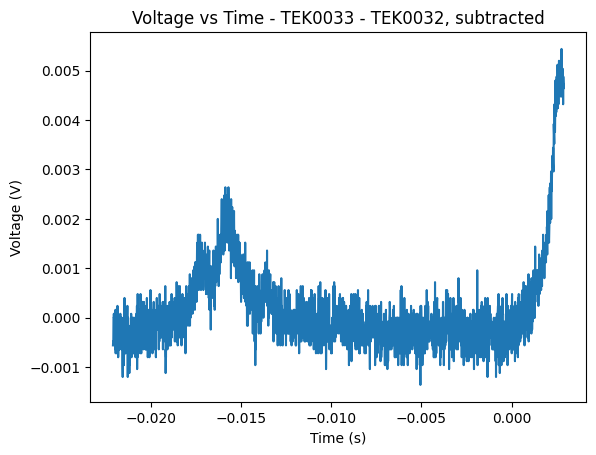

35
34


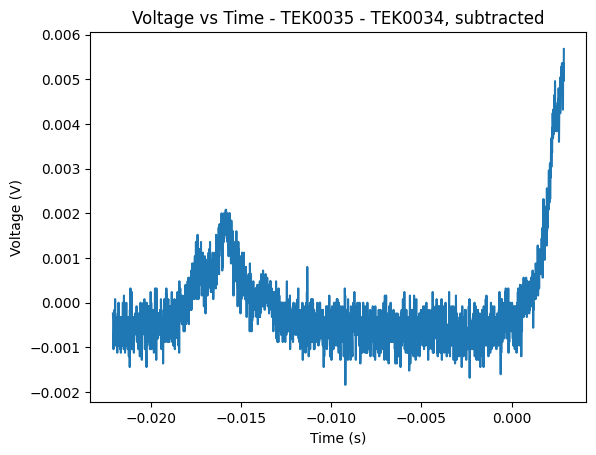

37
36


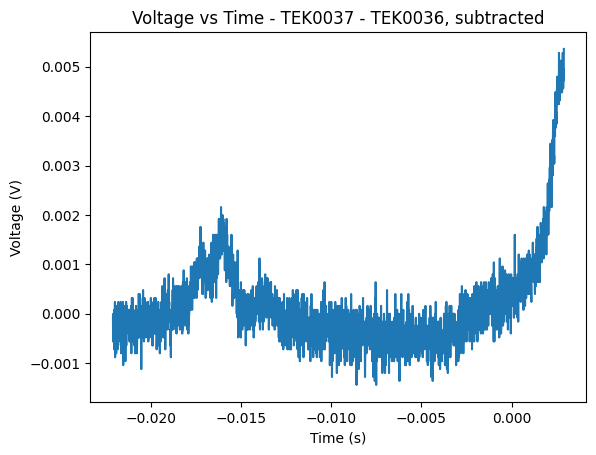

39
38


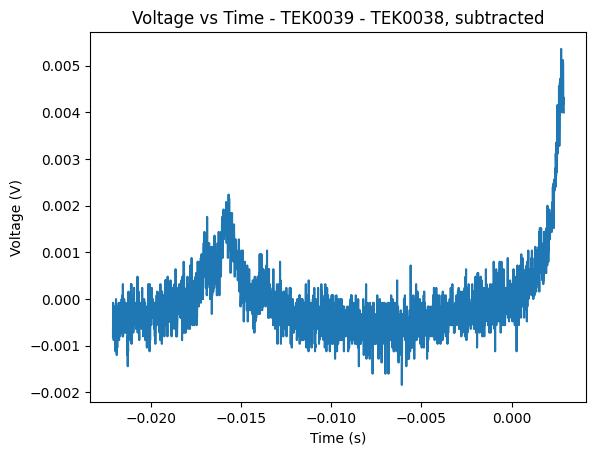

41
40


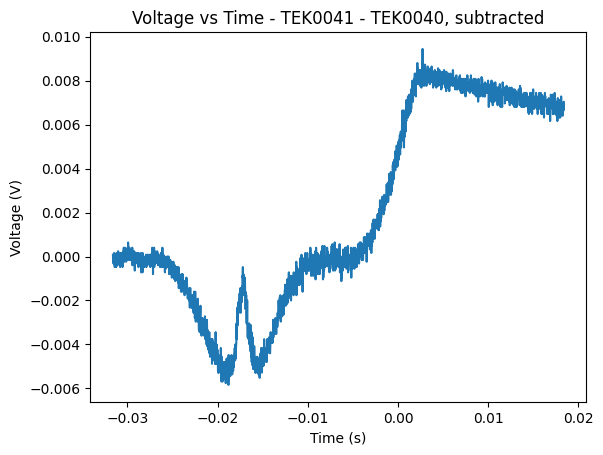

43
42


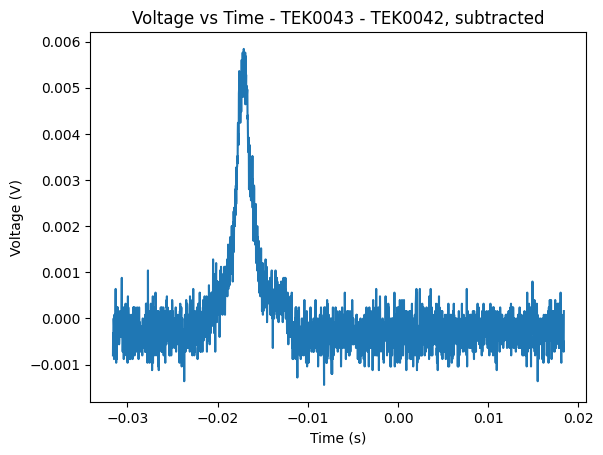

45
44


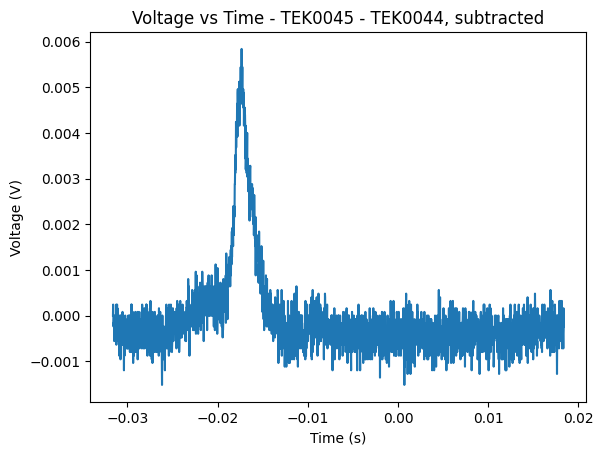

47
46


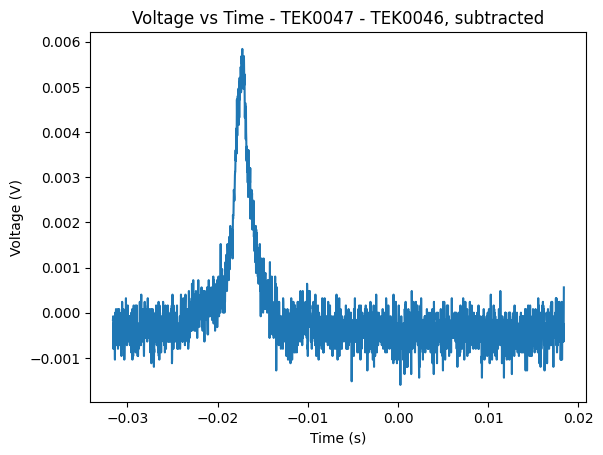

49
48


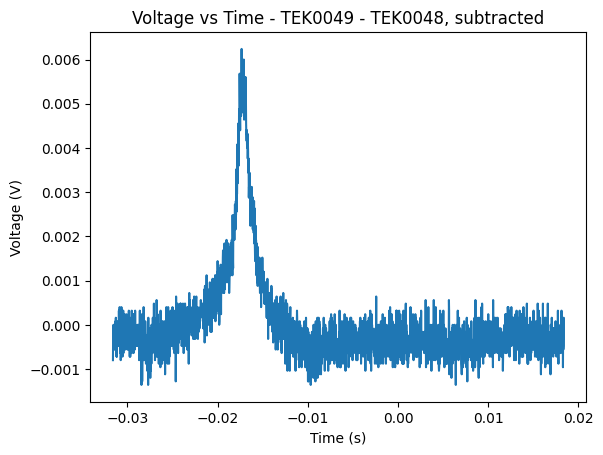

51
50


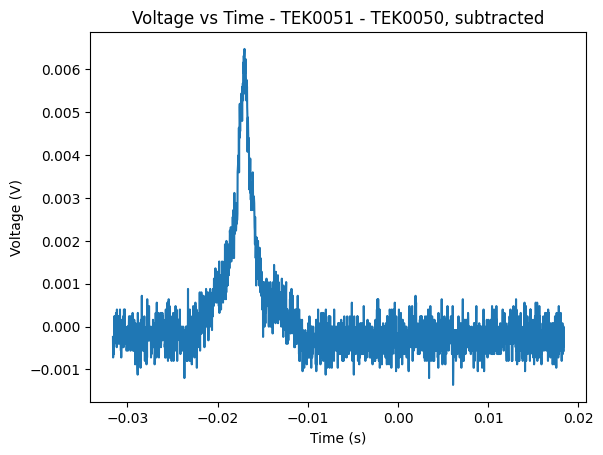

53
52


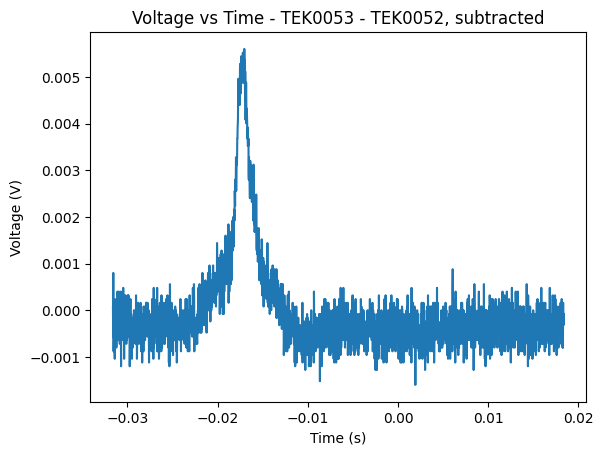

55
54


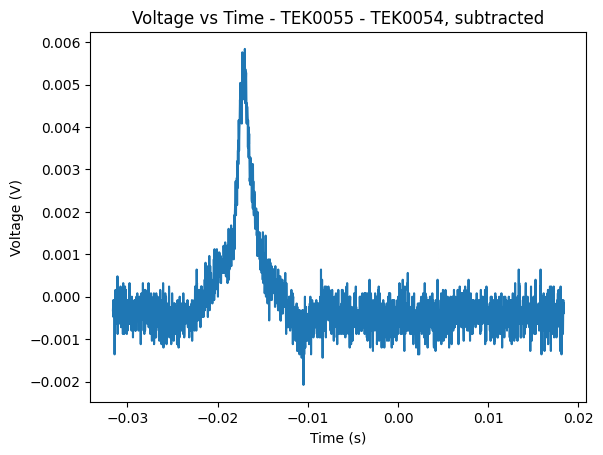

57
56


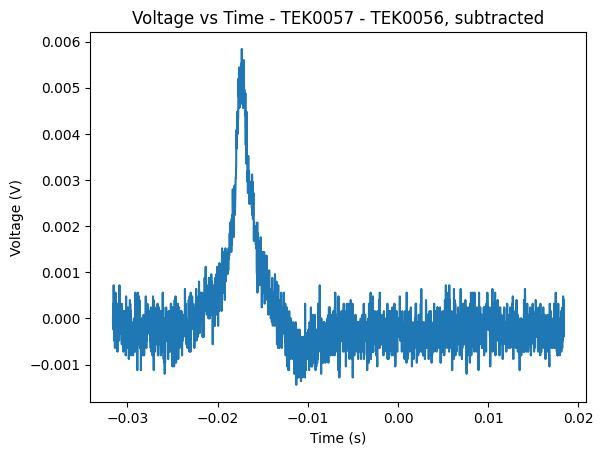

59
58


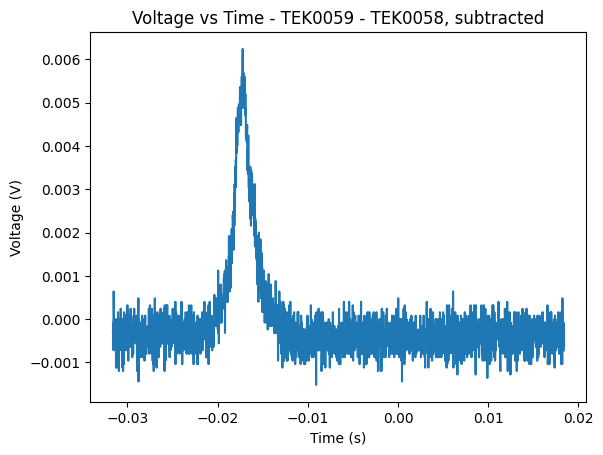

61
60


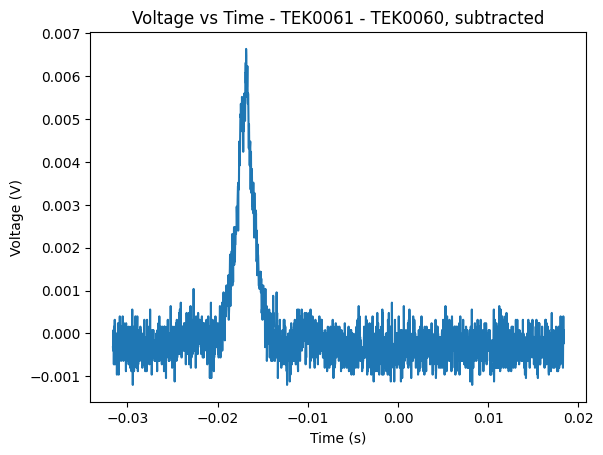

63
62


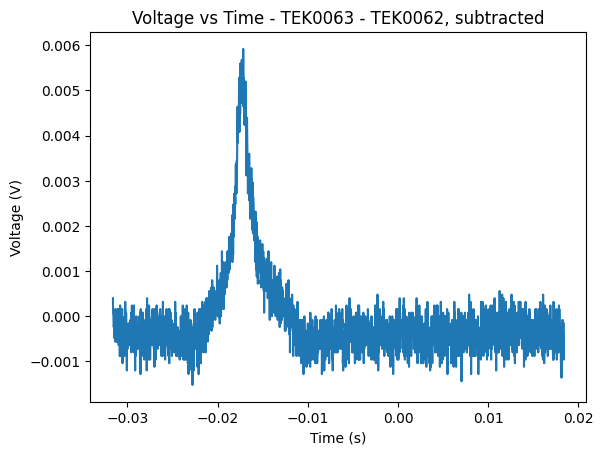

65
64


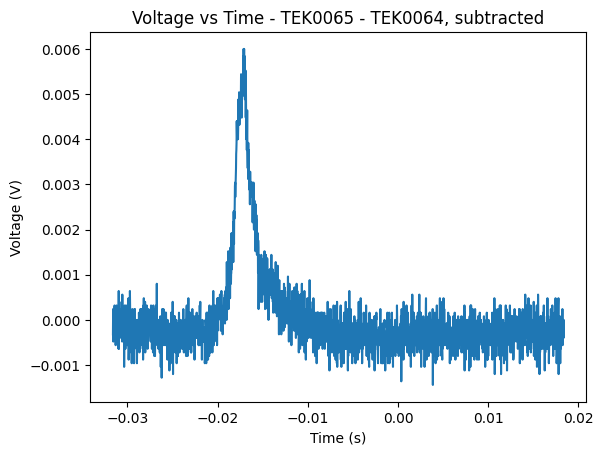

67
66


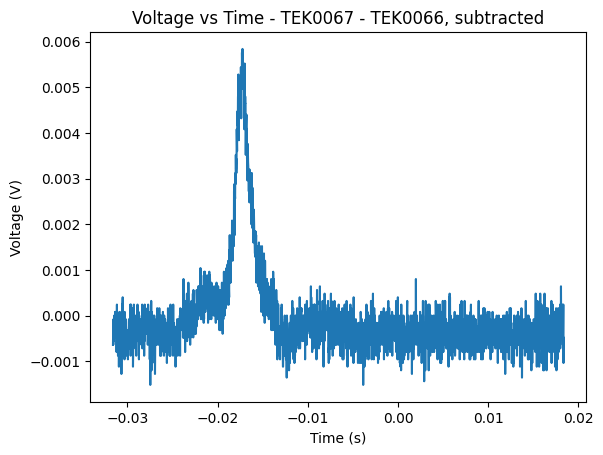

69
68


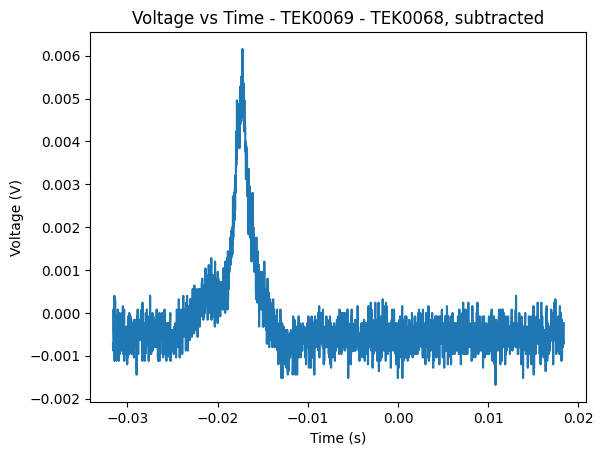

71
70


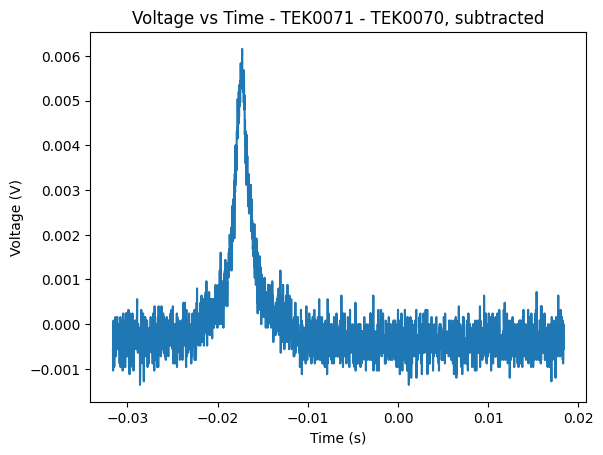

73
72


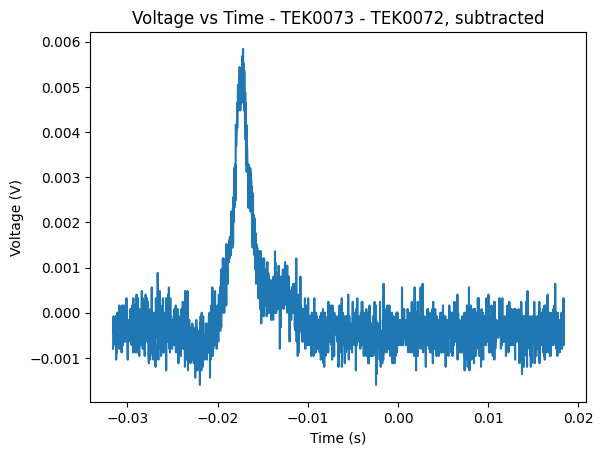

75
74


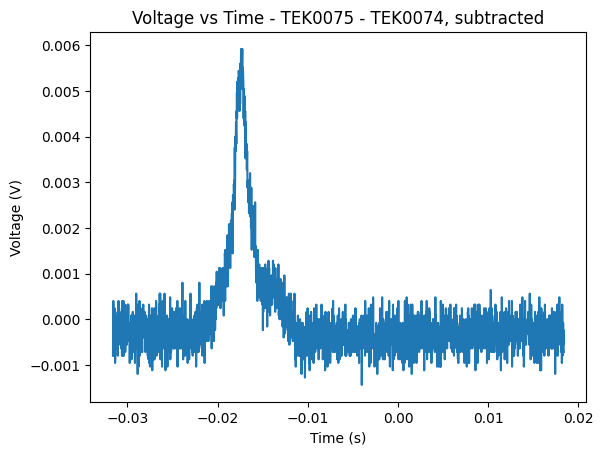

77
76


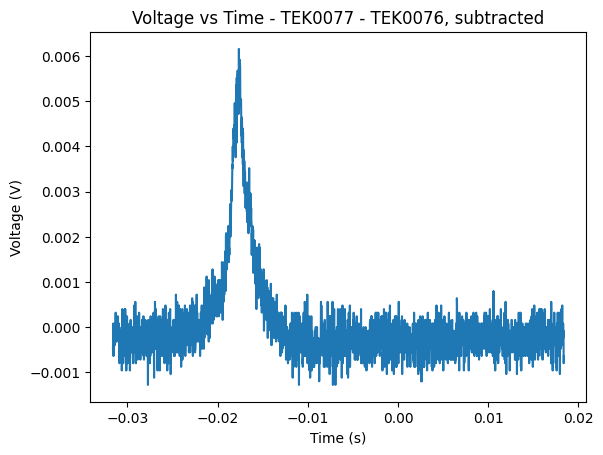

79
78


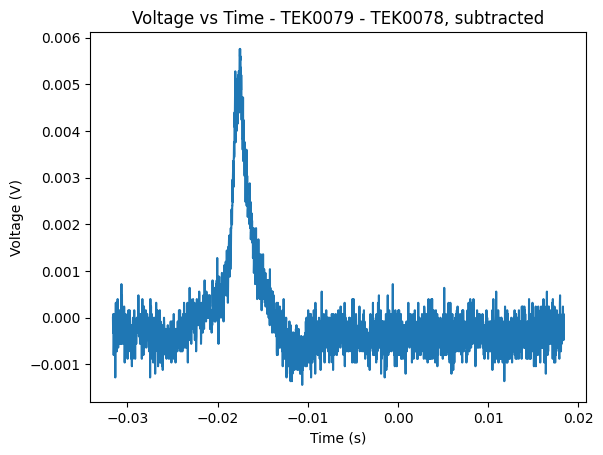

81
80


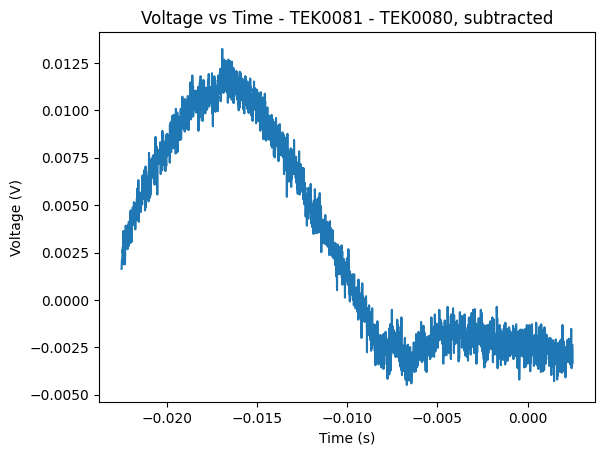

83
82


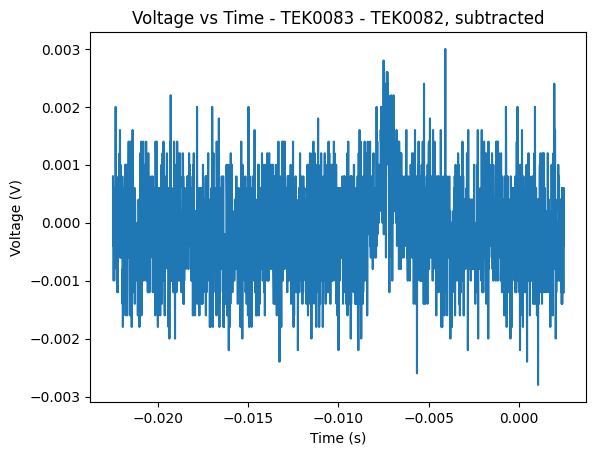

85
84


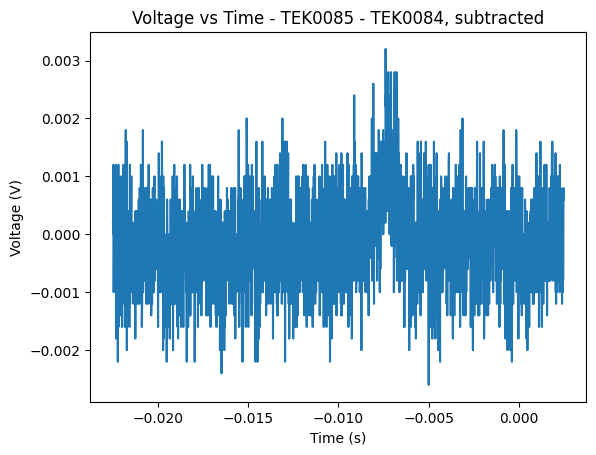

87
86


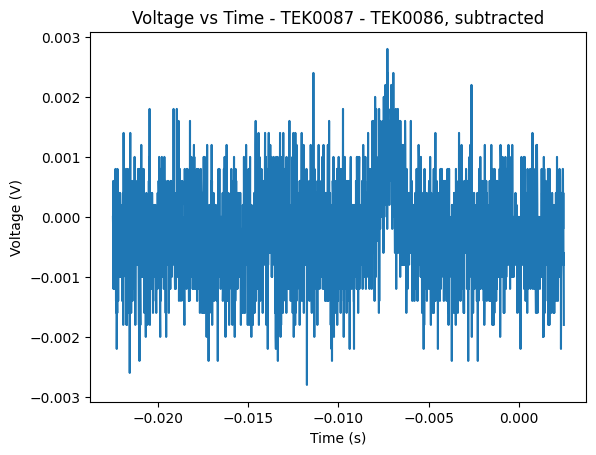

89
88


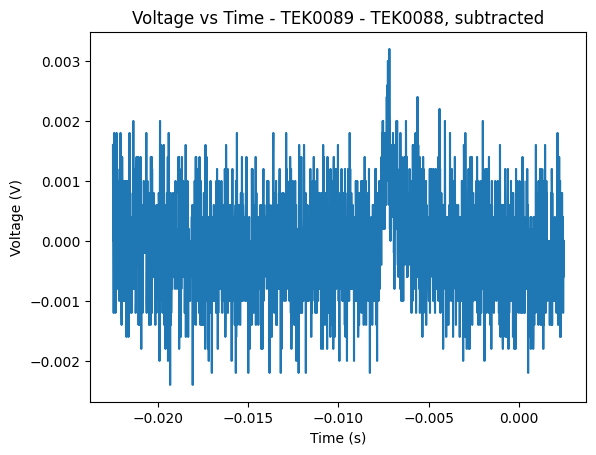

91
90


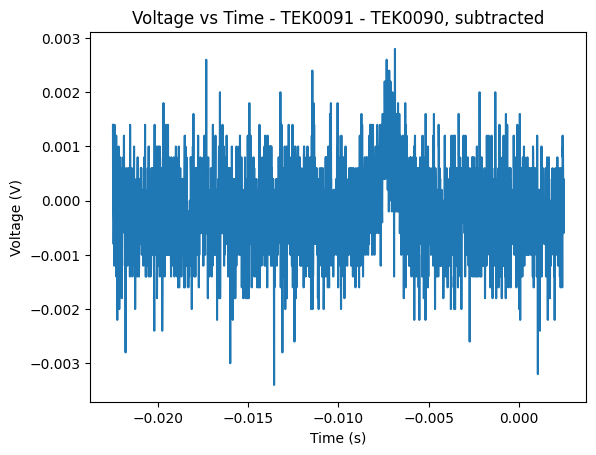

93
92


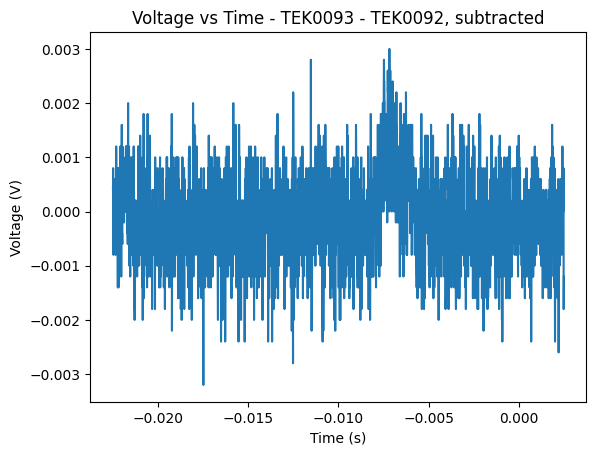

95
94


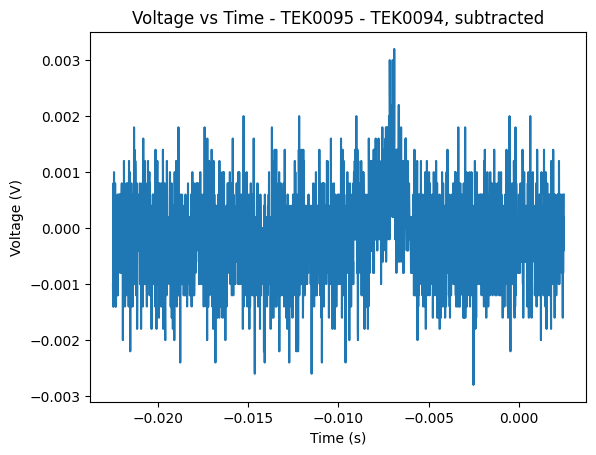

97
96


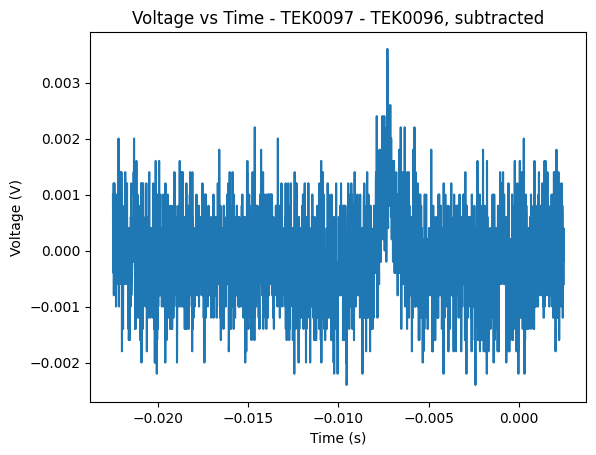

99
98


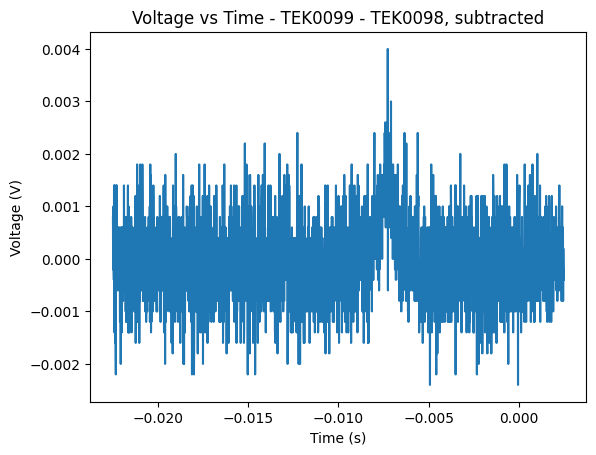

101
100


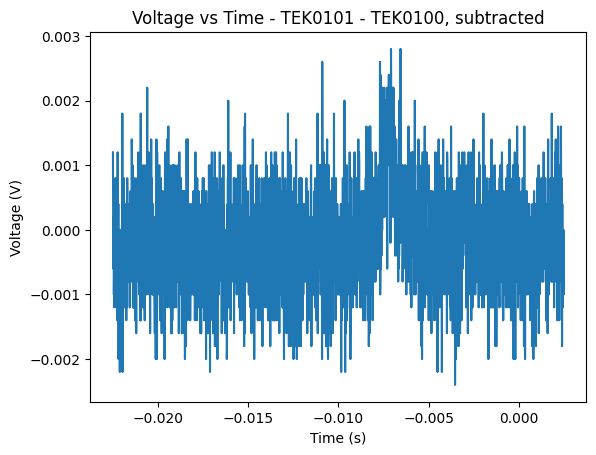

103
102


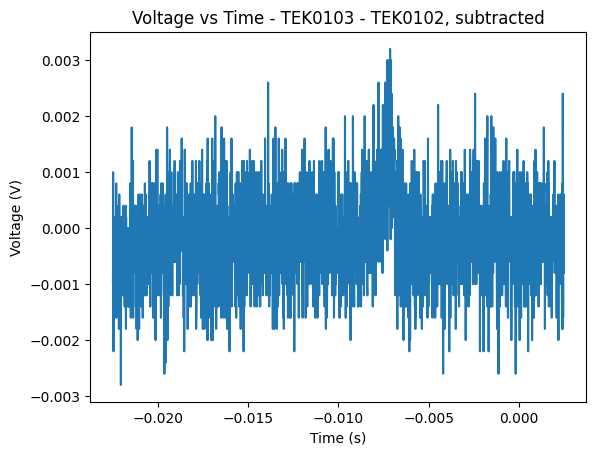

105
104


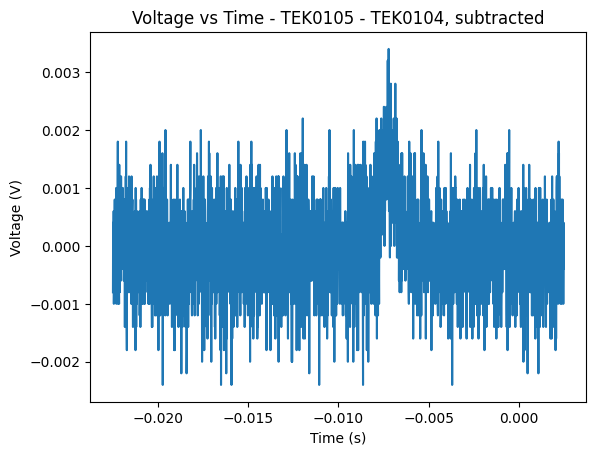

107
106


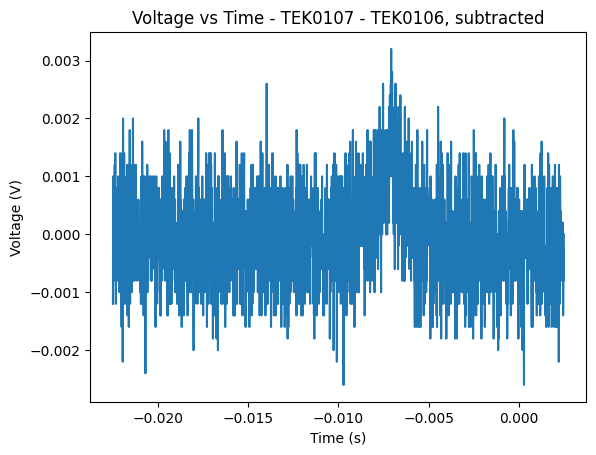

109
108


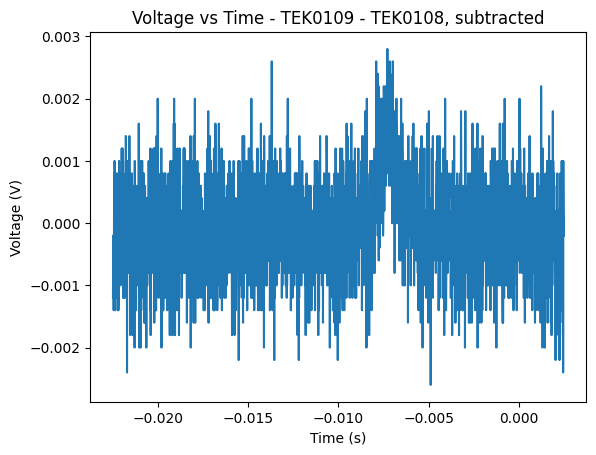

111
110


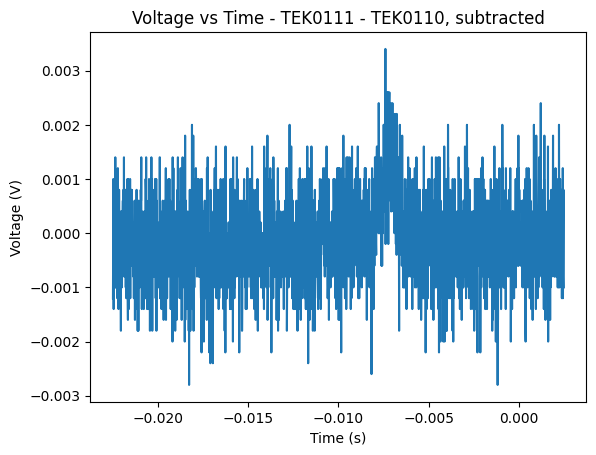

113
112


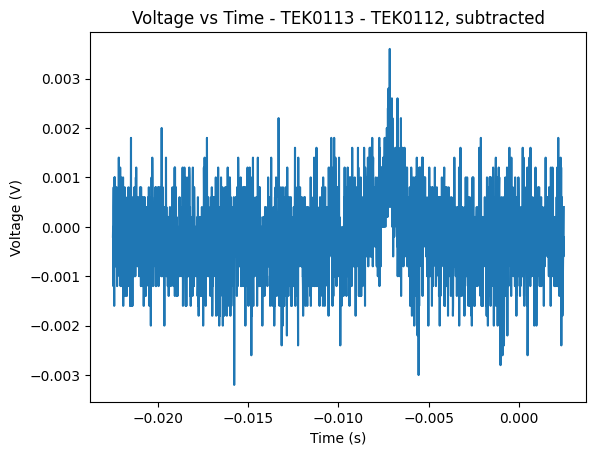

115
114


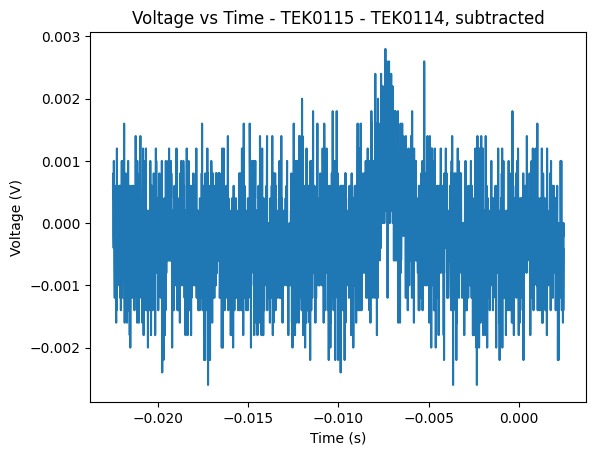

117
116


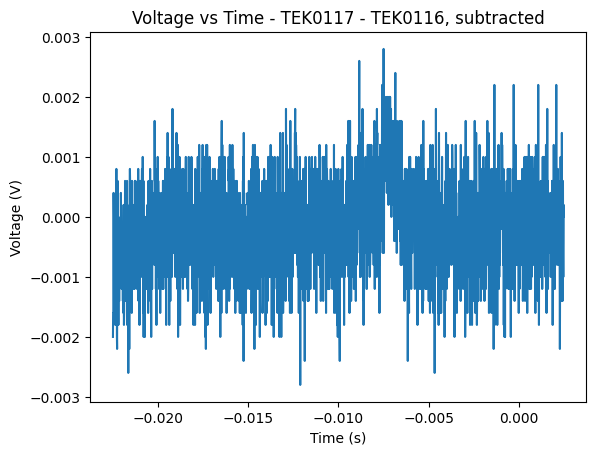

119
118


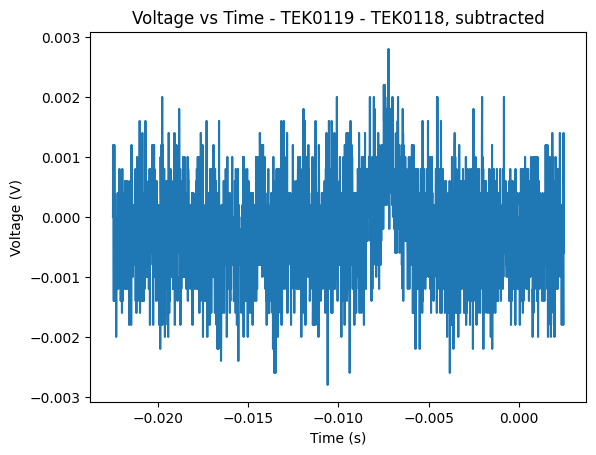

121
120


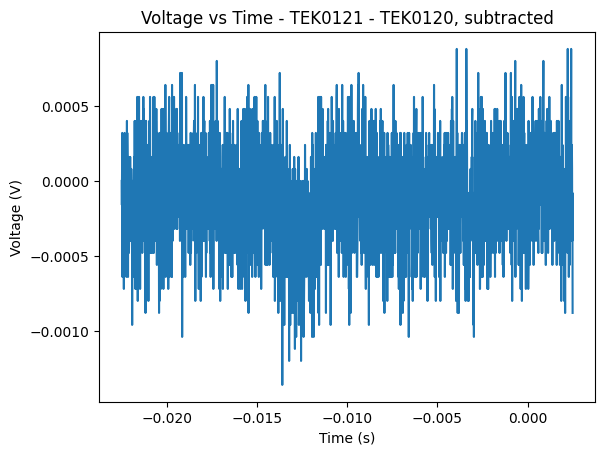

123
122


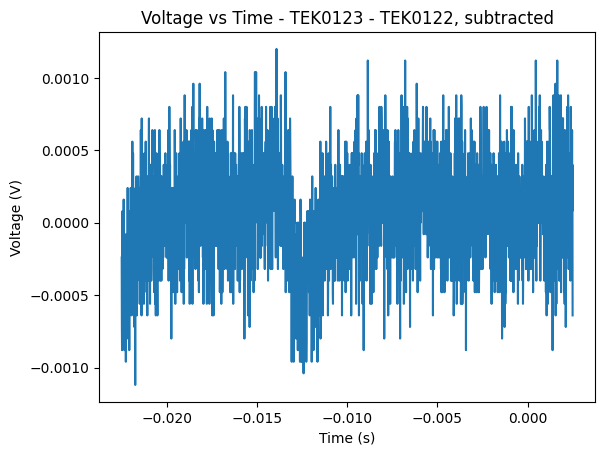

125
124


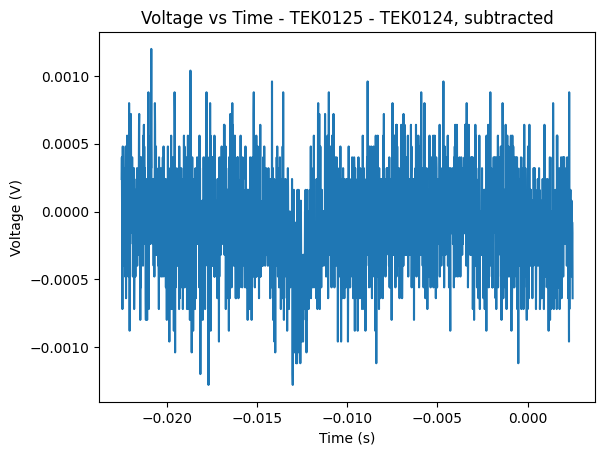

127
126


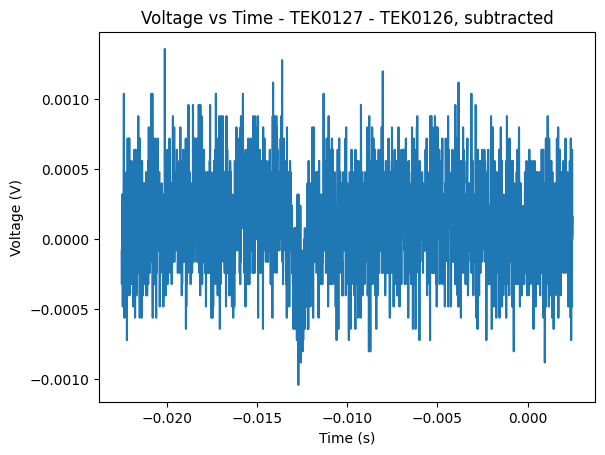

129
128


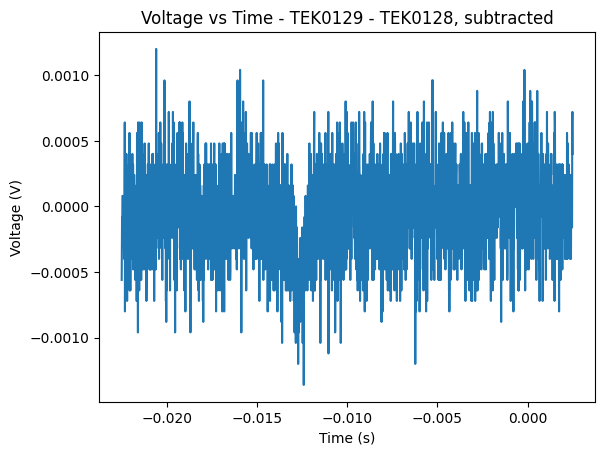

131
130


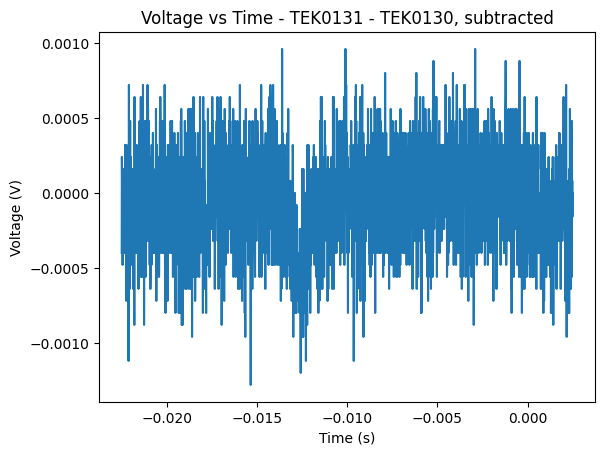

133
132


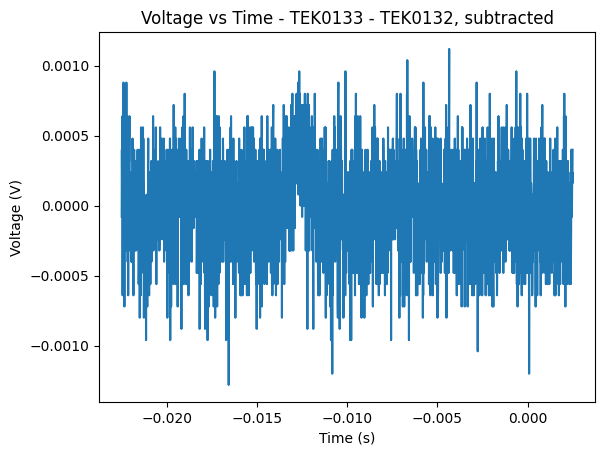

135
134


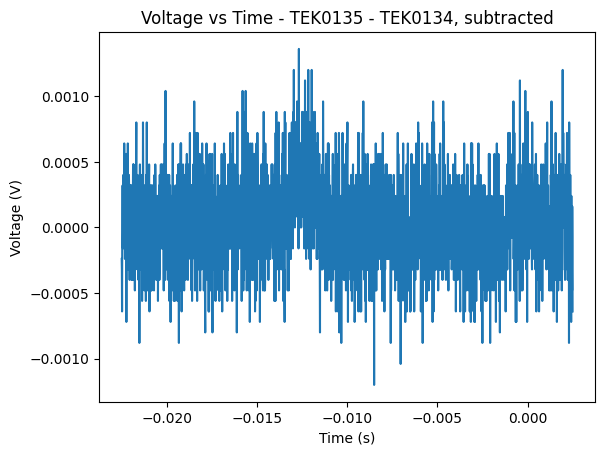

137
136


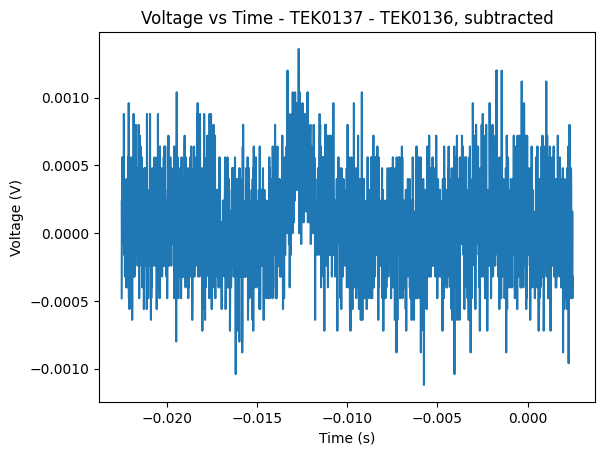

139
138


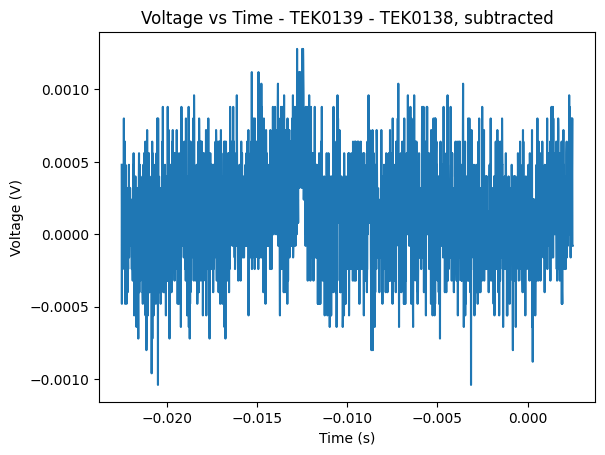

141
140


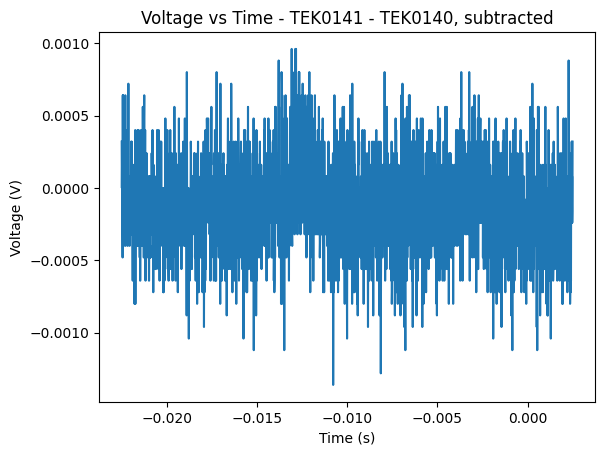

143
142


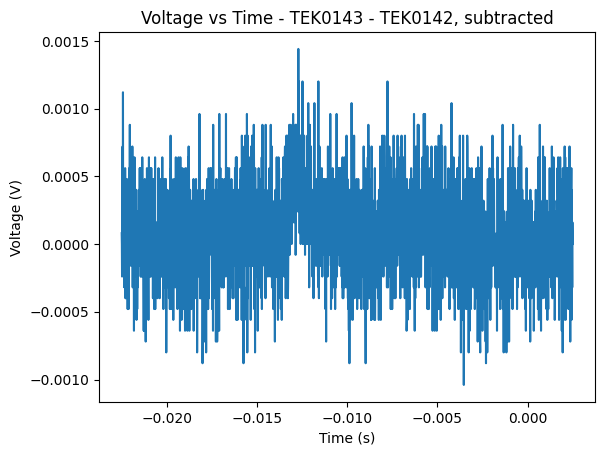

145
144


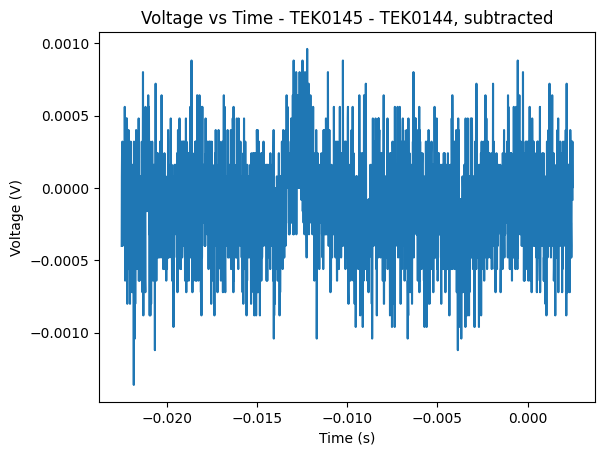

147
146


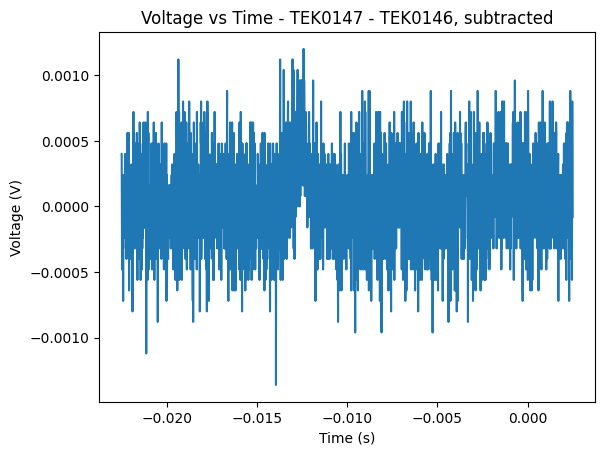

149
148


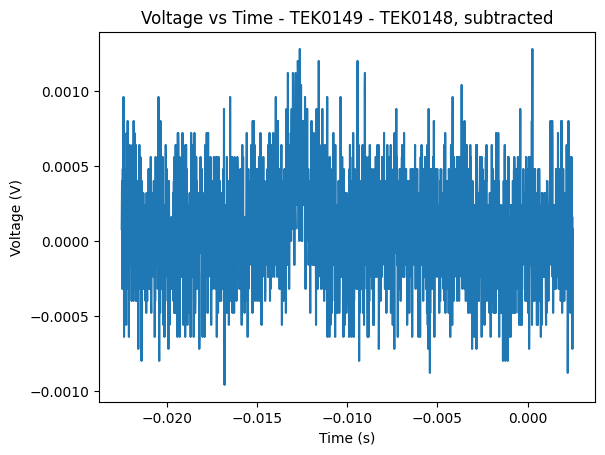

151
150


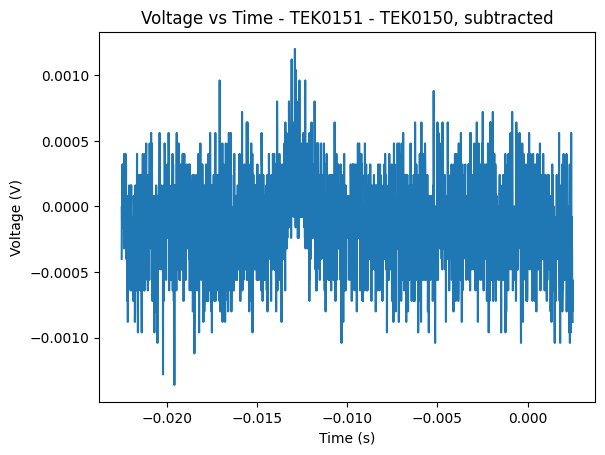

153
152


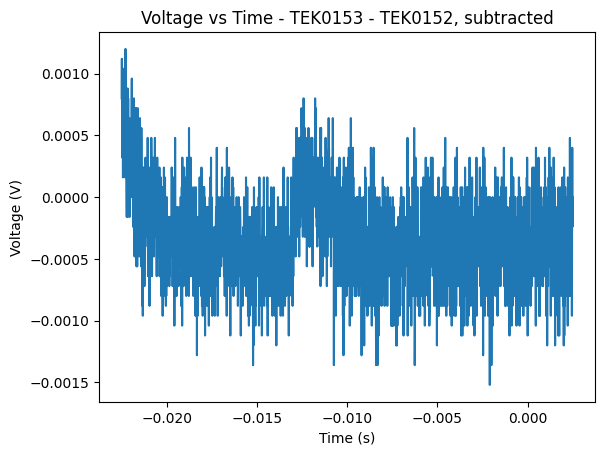

155
154


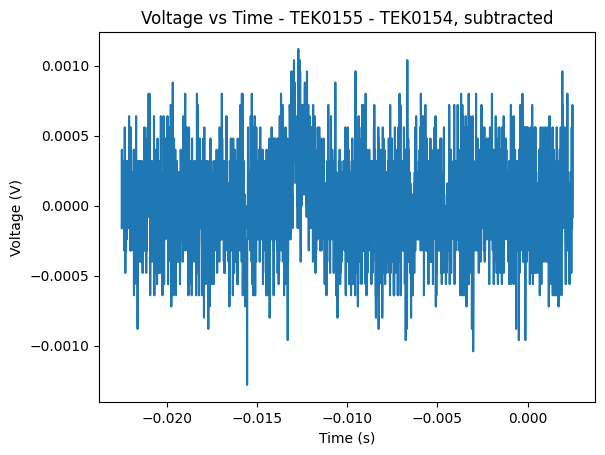

157
156


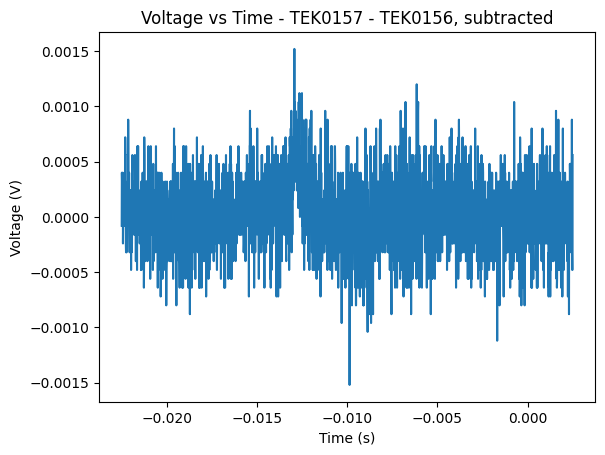

159
158


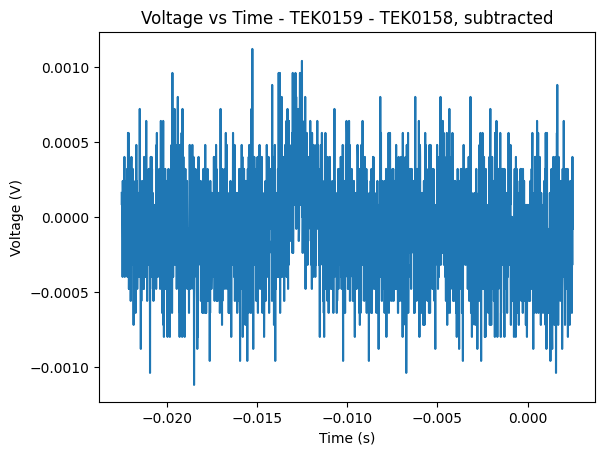

161
160


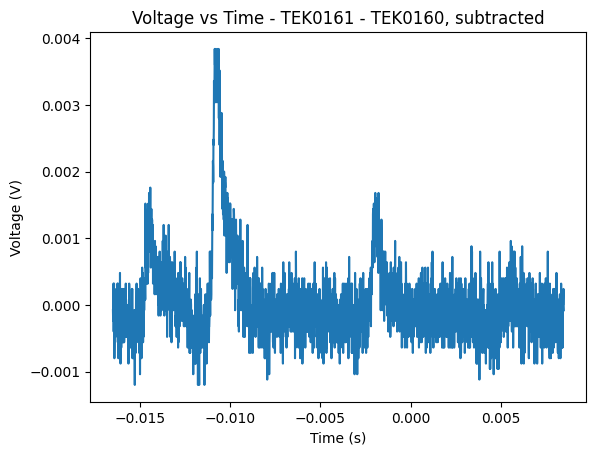

163
162


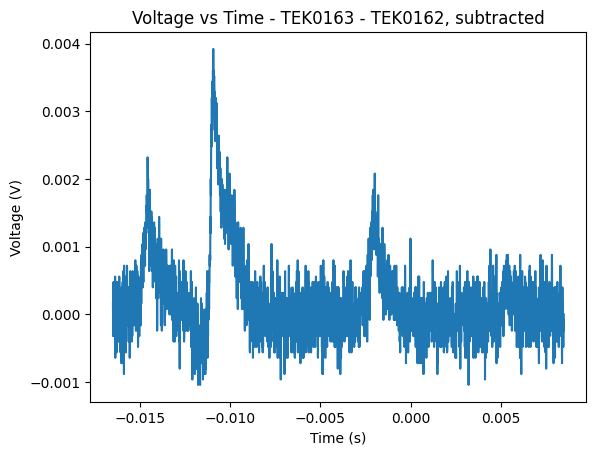

165
164


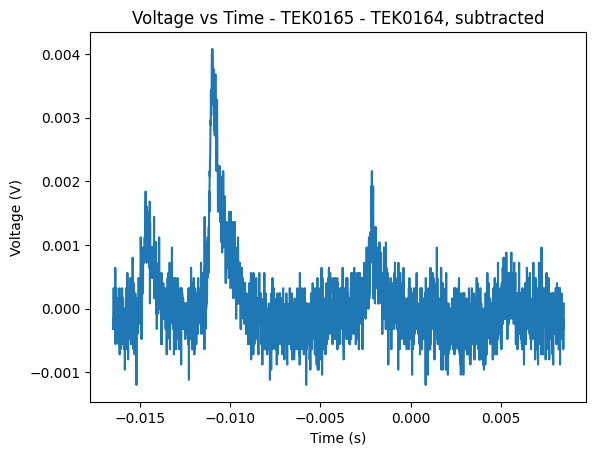

167
166


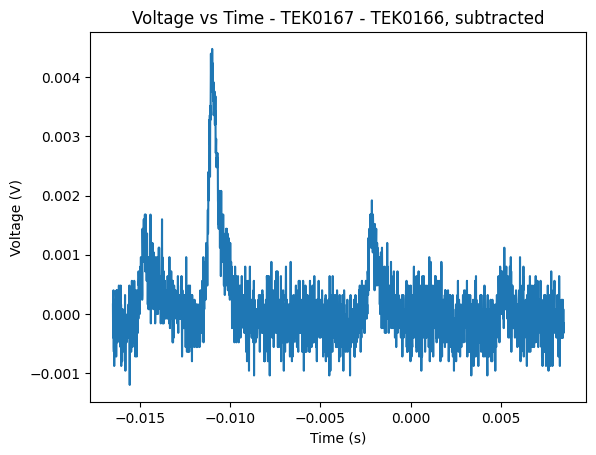

169
168


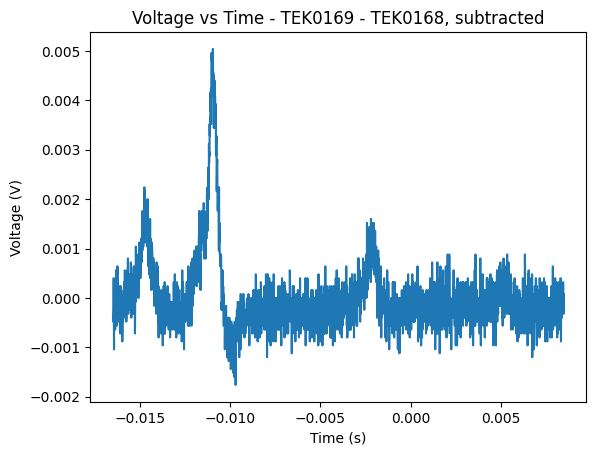

171
170


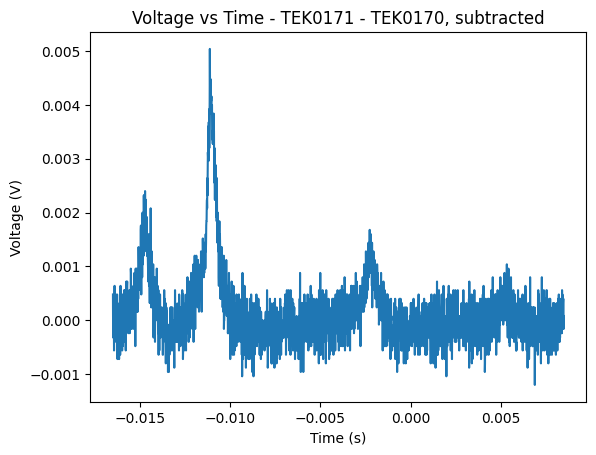

173
172


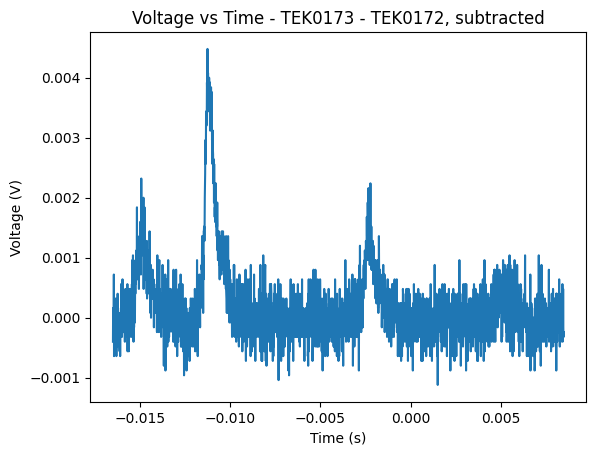

175
174


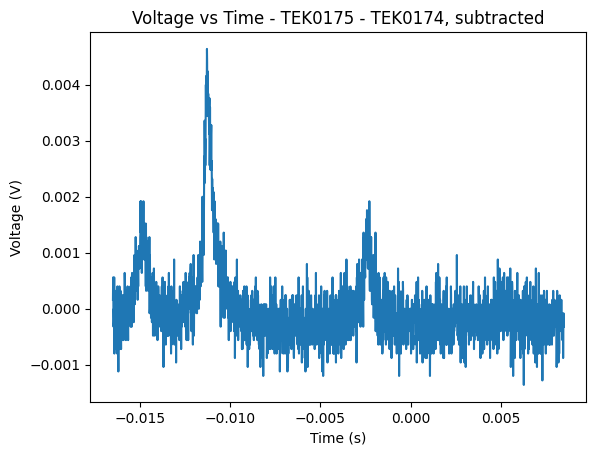

177
176


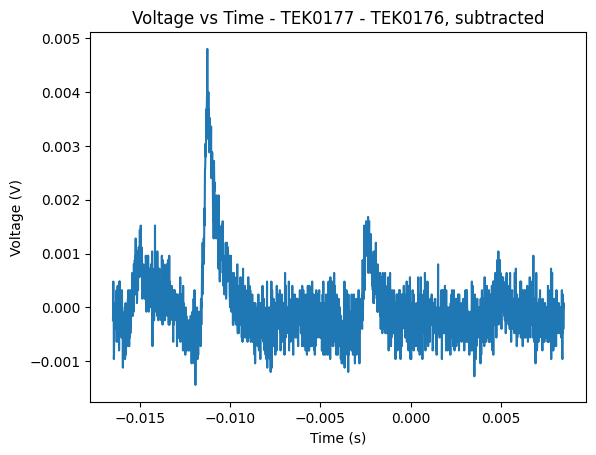

179
178


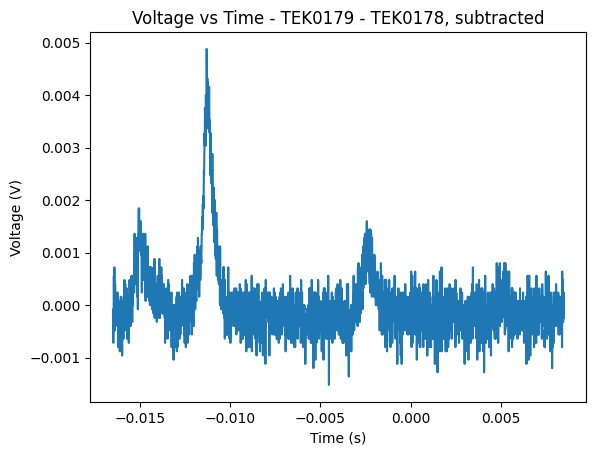

181
180


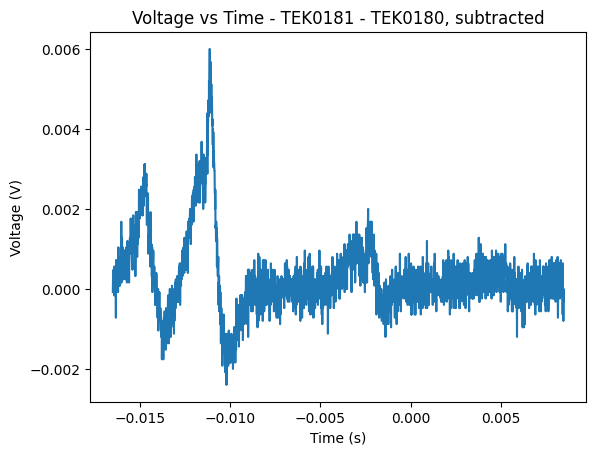

183
182


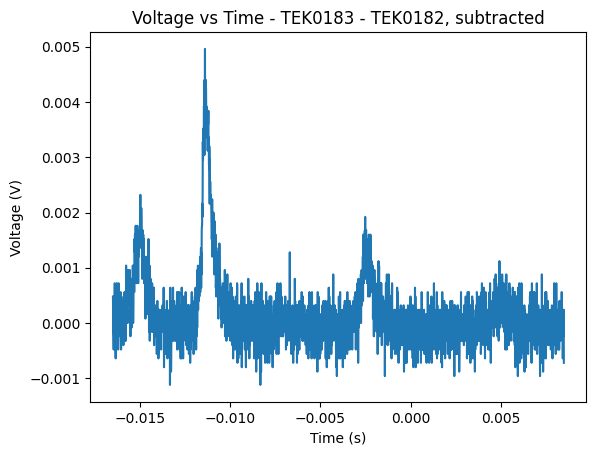

185
184


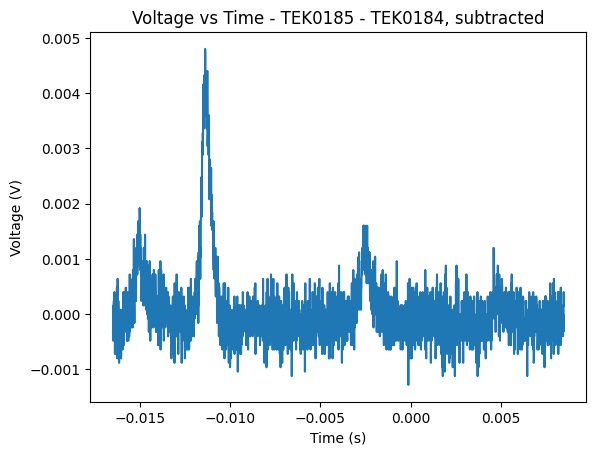

187
186


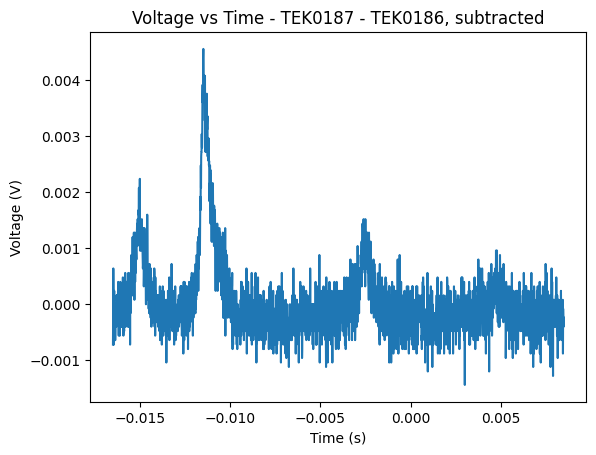

189
188


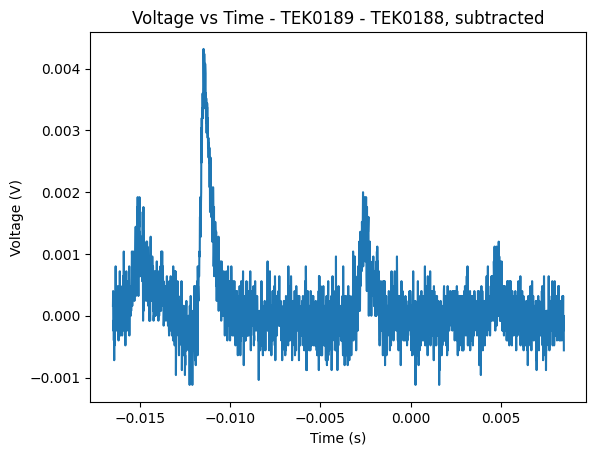

191
190


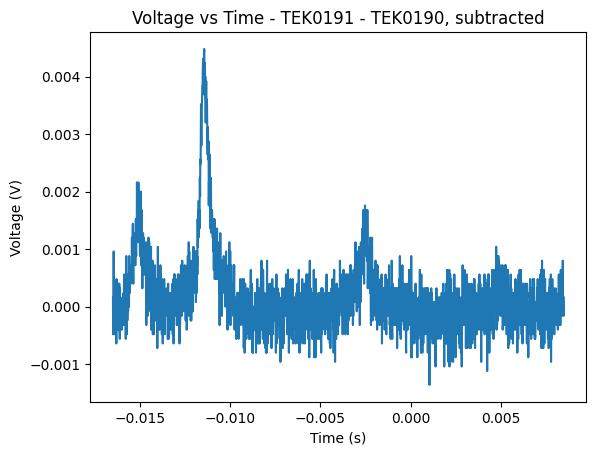

193
192


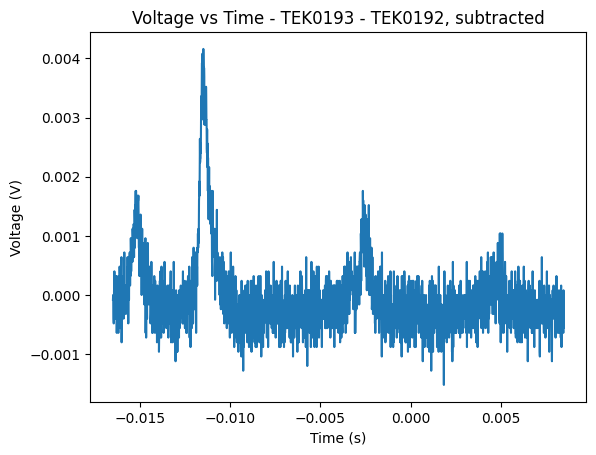

195
194


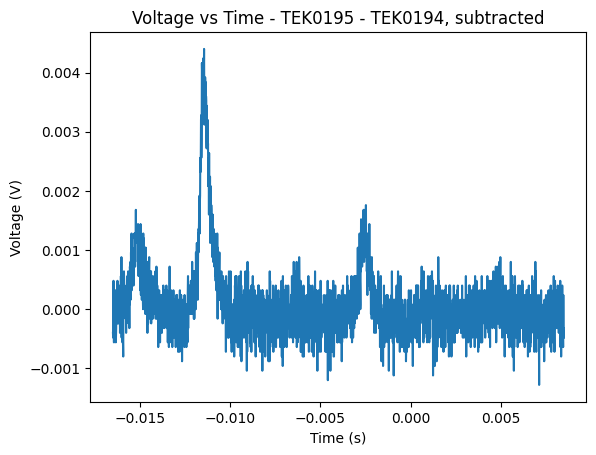

197
196


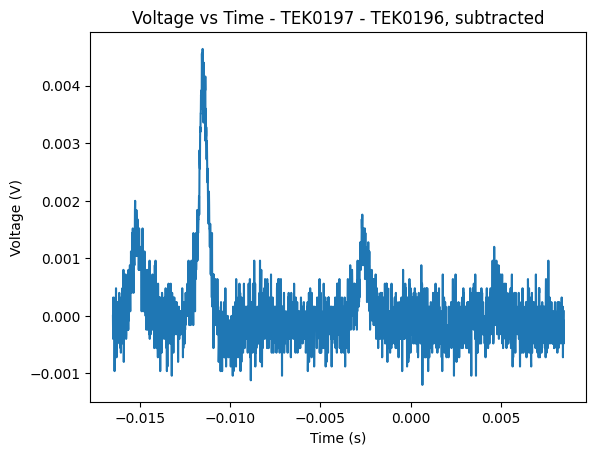

199
198


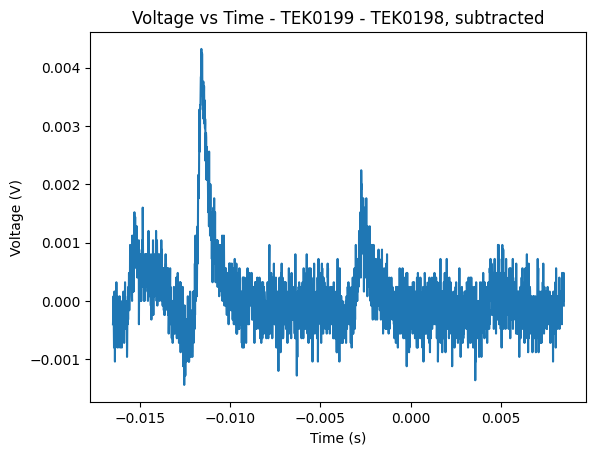

In [72]:
#Importeren van de Data: 
folder_pad = r"/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Alle_data_real, gotten on 2026_06_09 and 2026_06_10"

x_subs, y_subs = file_data(folder_pad, 200)



In [109]:
x_peak_1 = []
y_peak_1 = []

x_peak_2 = []
y_peak_2 =[]

x_peak_3 = []
y_peak_3 = []

x_peak_4 = []
y_peak_4 = []

x_all_peak = []
y_all_peak = []

for i in range (0,20):
    x_peak_1.append(x_subs[i])
    y_peak_1.append(y_subs[i])

for i in range (20,40):
    x_peak_2.append(x_subs[i])
    y_peak_2.append(y_subs[i])

for i in range (40,60):
    x_peak_3.append(x_subs[i])
    y_peak_3.append(y_subs[i])

for i in range (60,80):
    x_peak_4.append(x_subs[i])
    y_peak_4.append(y_subs[i])

for i in range (80,100):
    x_all_peak.append(x_subs[i])
    y_all_peak.append(y_subs[i])



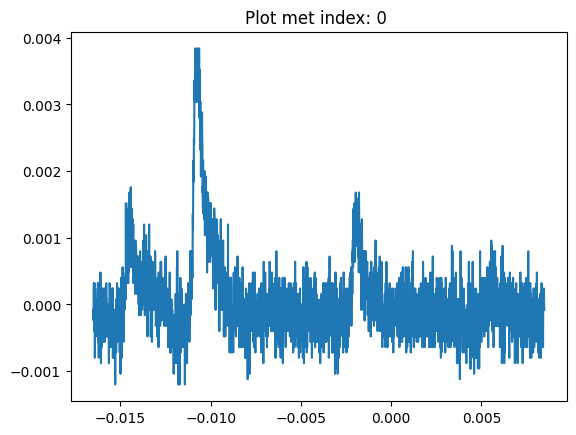

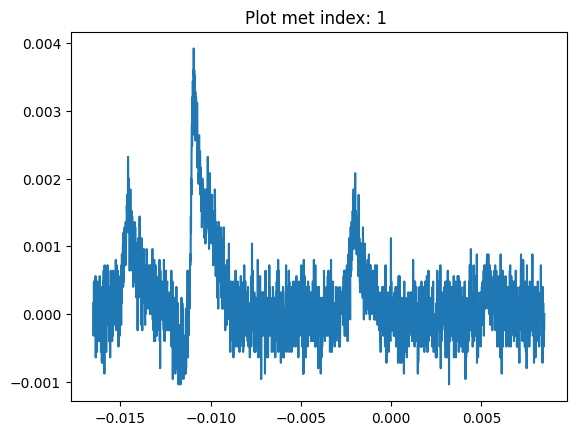

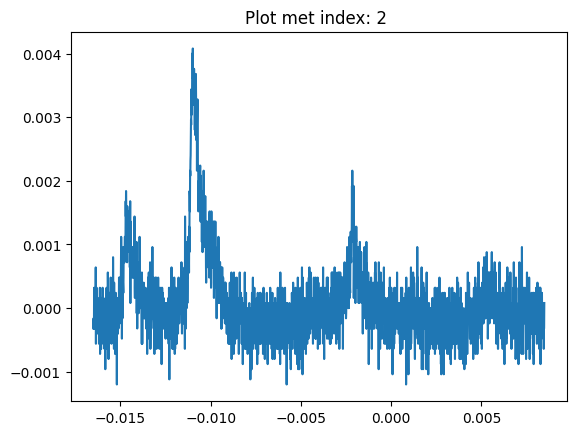

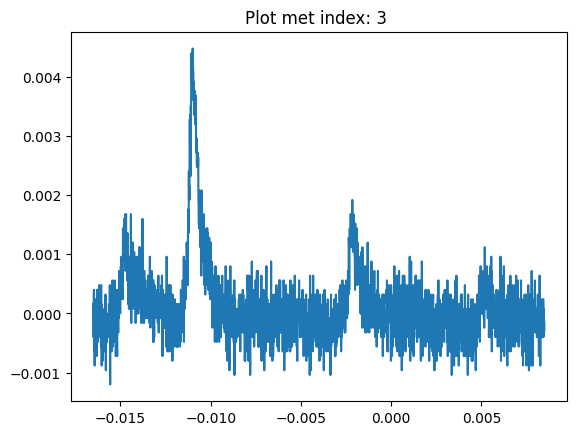

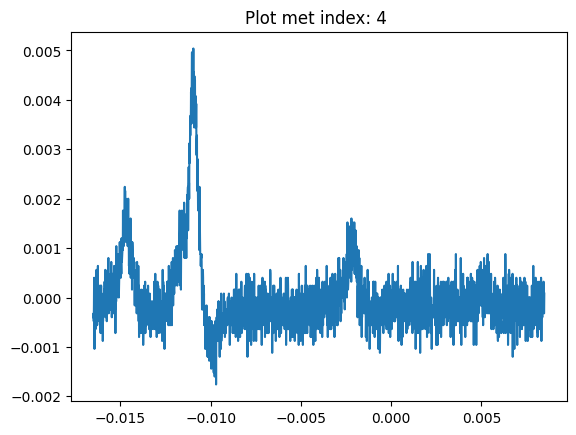

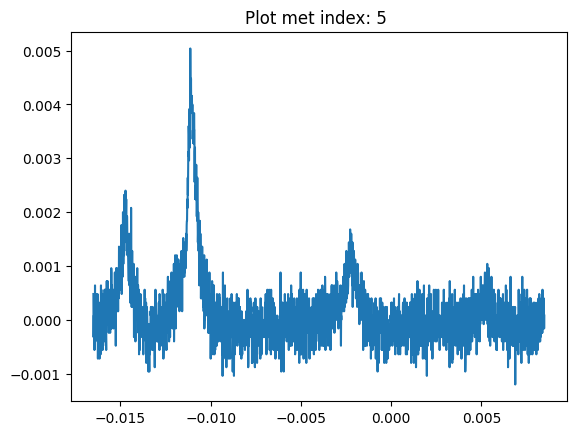

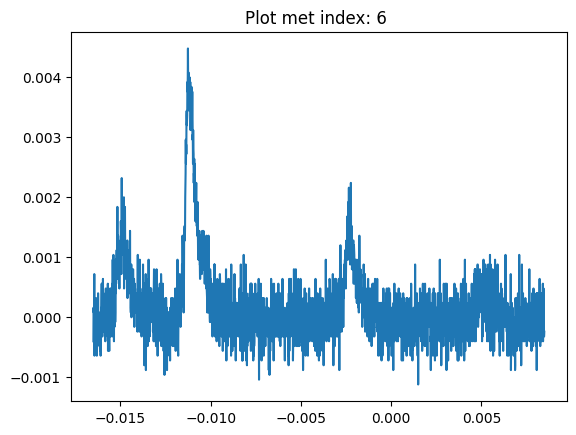

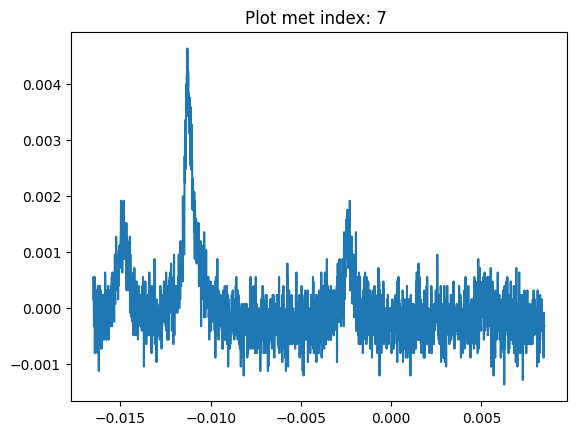

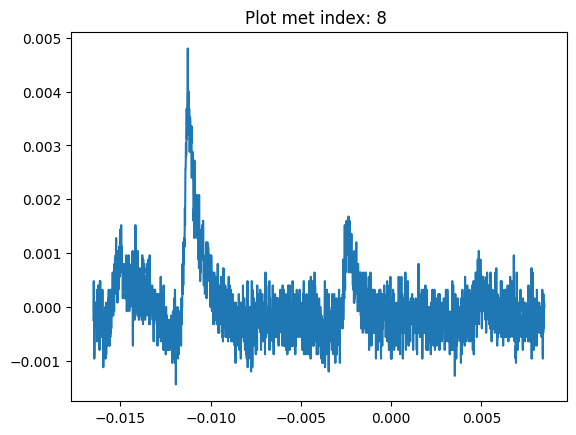

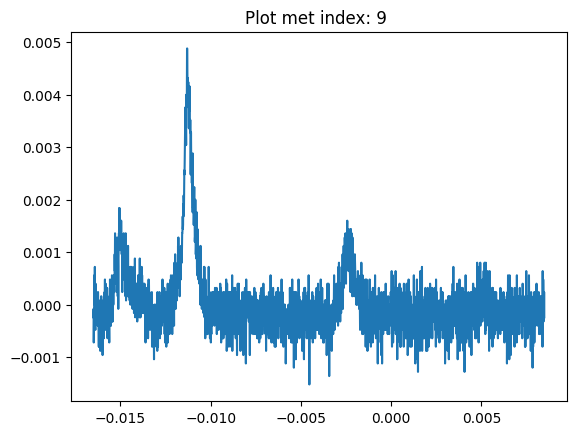

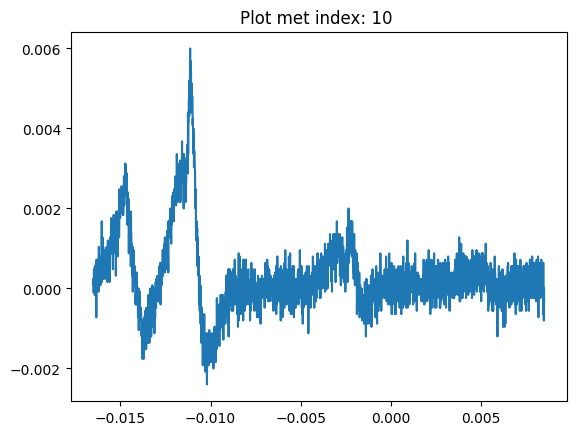

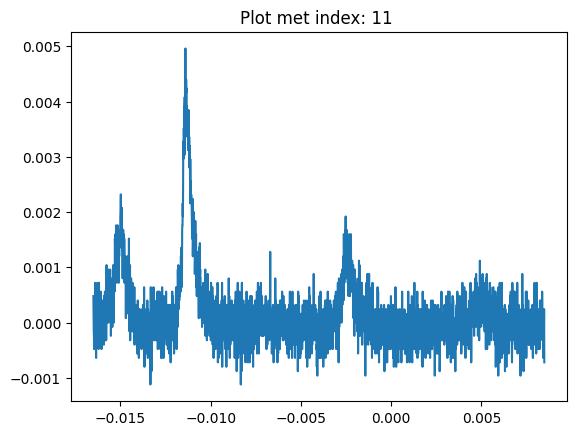

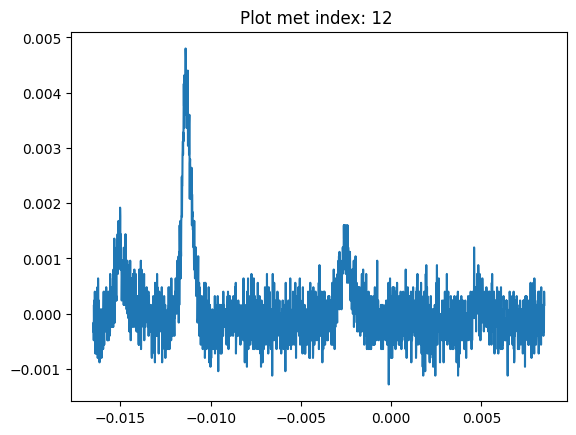

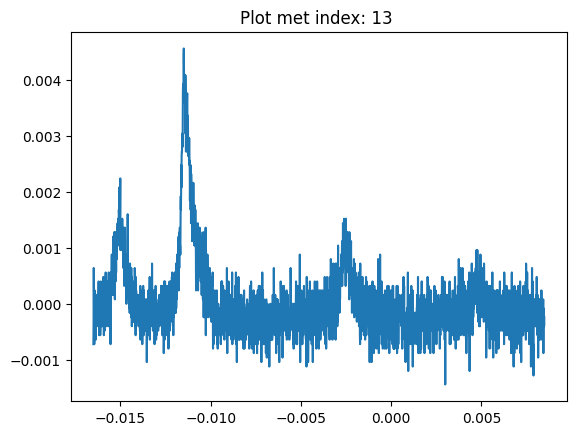

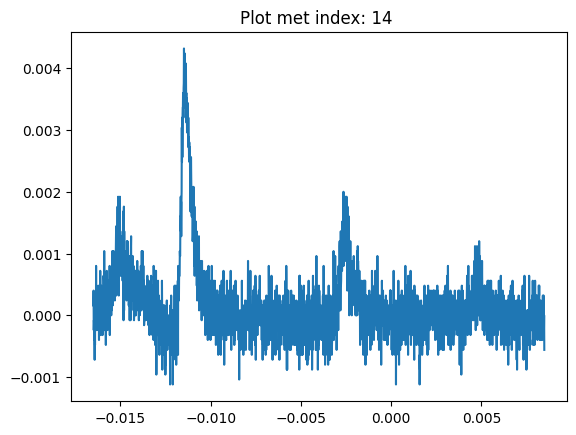

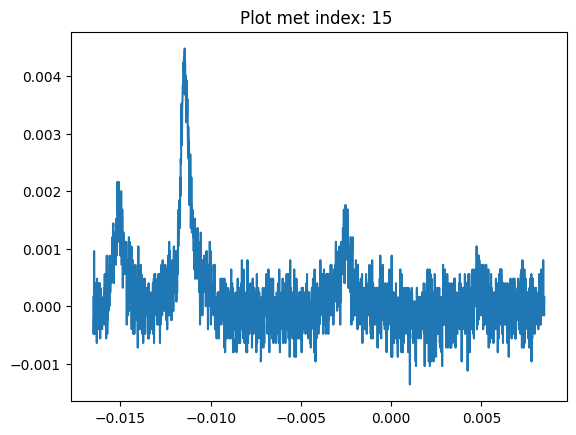

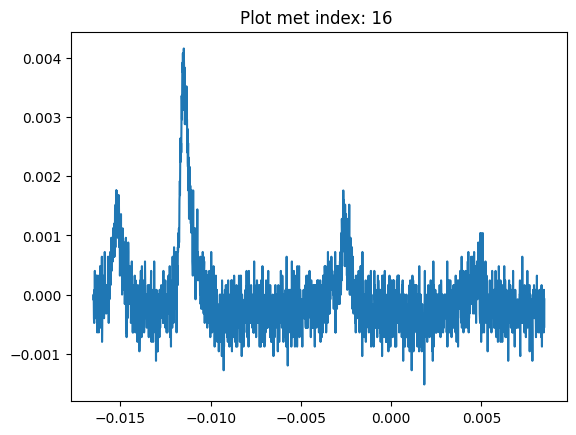

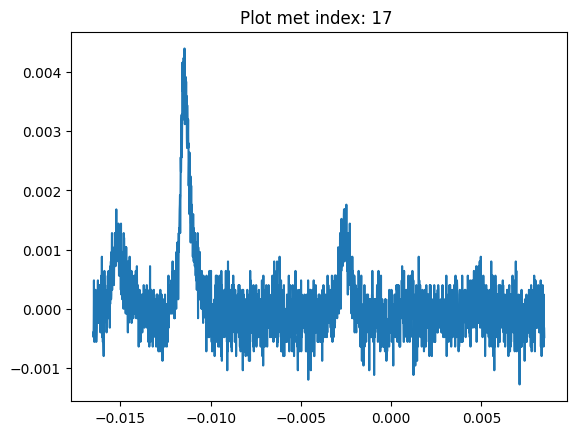

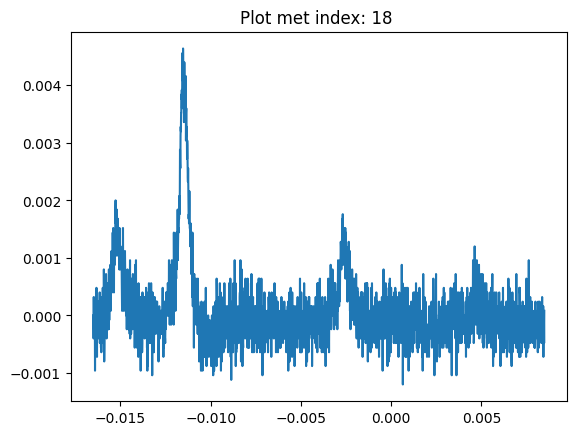

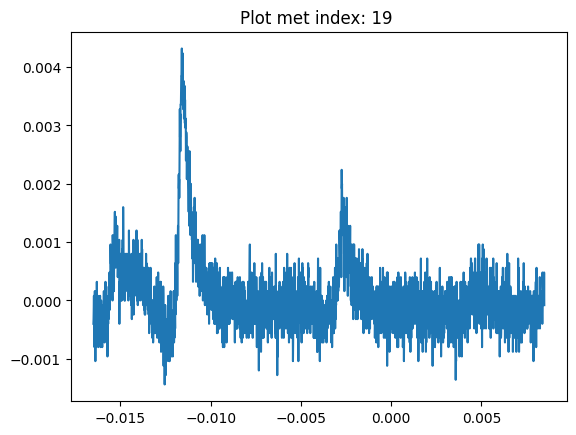

In [119]:
#Plot some:

for i in range (0,len(x_all_peak)):
    plt.plot(x_all_peak[i],y_all_peak[i])
    plt.title(f"Plot met index: {i} ")
    plt.show()
    




In [120]:
#We also need to delete some :(
x_peak_1.pop(7)
y_peak_1.pop(7)

x_peak_2.pop(0)
y_peak_2.pop(0)

x_peak_3.pop(0)
y_peak_3.pop(0)


array([0.0002, 0.    , 0.0012, ..., 0.0008, 0.0006, 0.0006], shape=(2500,))

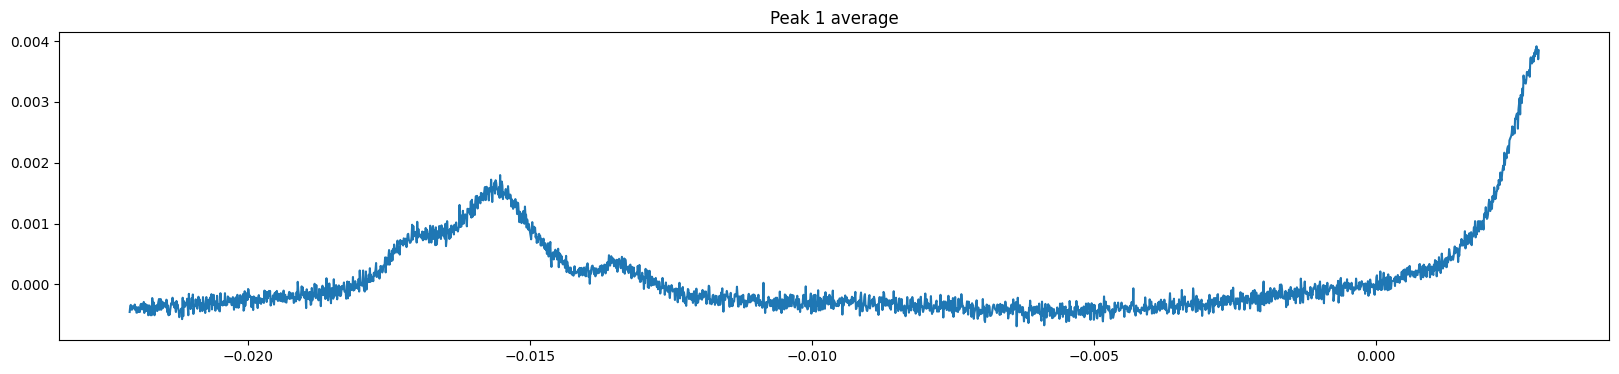

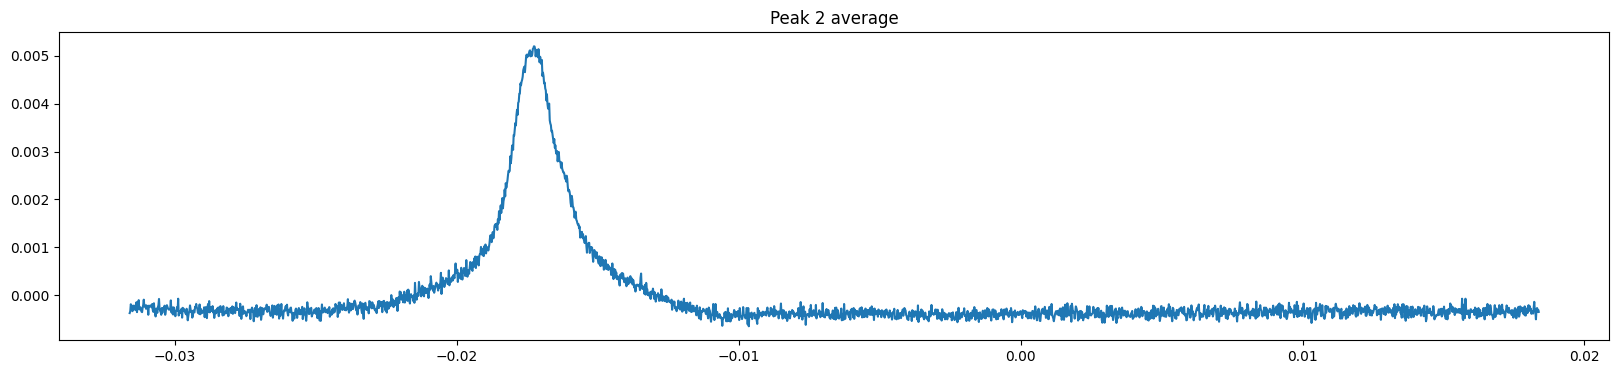

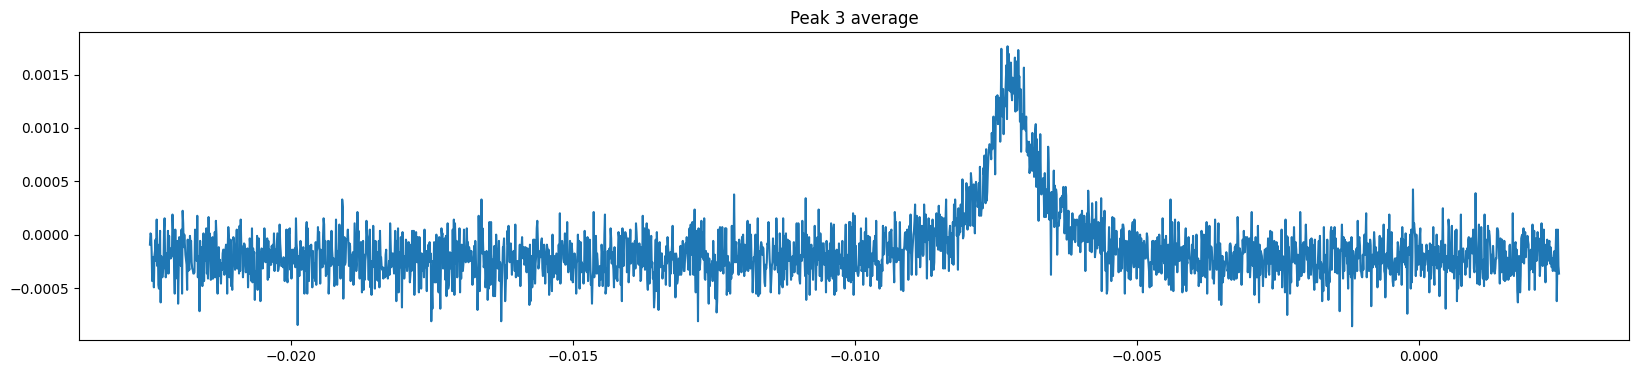

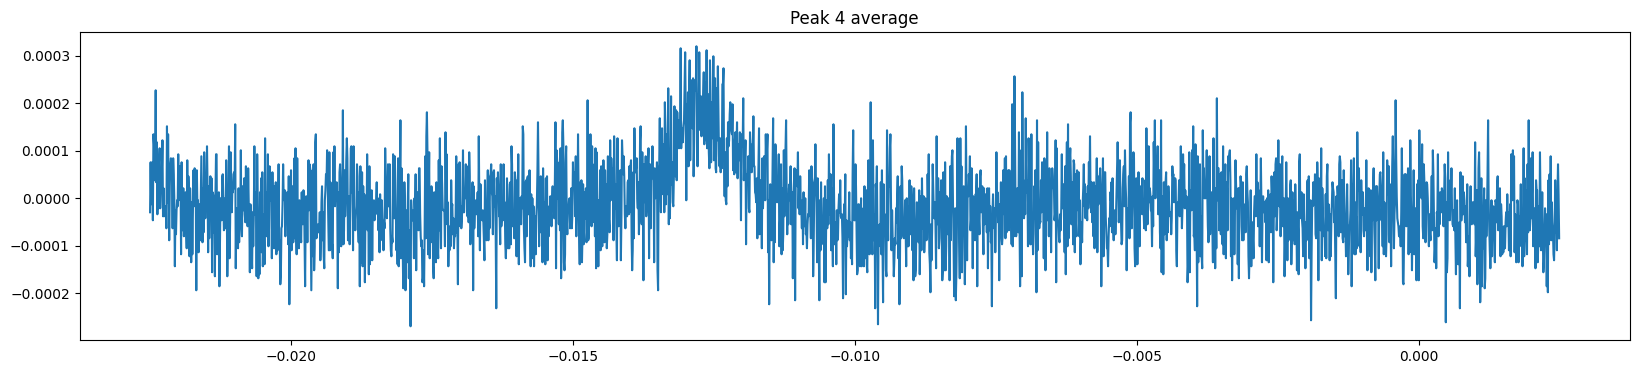

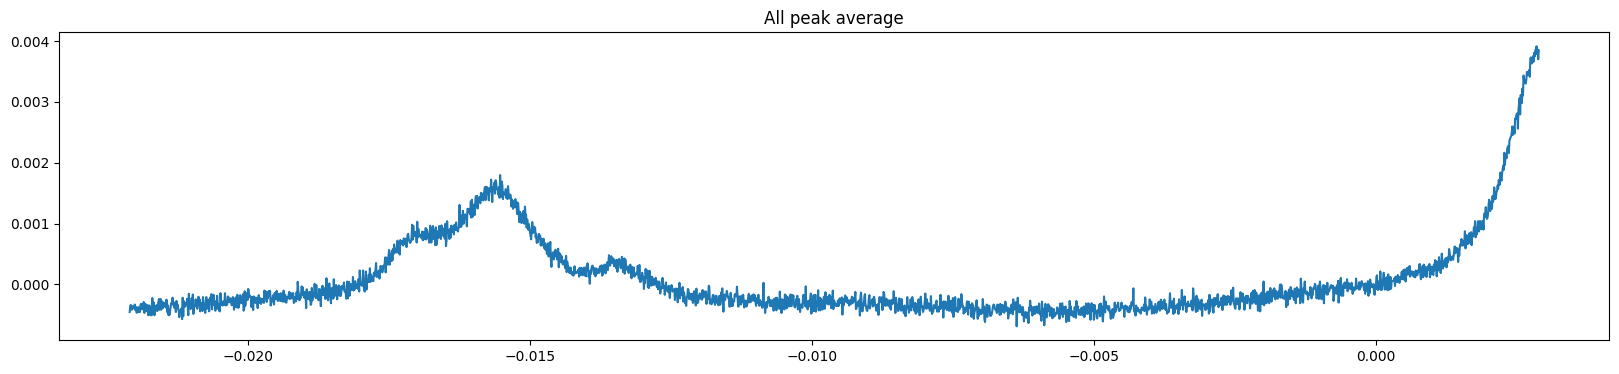

In [147]:
def gemiddelde_grafiek(x_lijst, y_lijst):

    # Gemeenschappelijk x-bereik: van het hoogste minimum tot het laagste maximum
    # (zodat alle grafieken overlappen op dit bereik)
    x_min = max(np.min(x) for x in x_lijst)
    x_max = min(np.max(x) for x in x_lijst)

    # Aantal punten = gemiddelde lengte van de sub-lijsten
    n_punten = int(np.mean([len(x) for x in x_lijst]))

    x_communal = np.linspace(x_min, x_max, n_punten)

    # Interpoleer elke grafiek op het gemeenschappelijke x-grid
    y_geinterpoleerd = np.array([
        np.interp(x_communal, x, y)
        for x, y in zip(x_lijst, y_lijst)
    ])

    # Gemiddelde over alle grafieken
    y_gemiddeld = np.mean(y_geinterpoleerd, axis=0)

    return x_communal, y_gemiddeld

x_avg_1,y_avg_1 = gemiddelde_grafiek(x_peak_1,y_peak_1)
x_avg_2,y_avg_2 = gemiddelde_grafiek(x_peak_2,y_peak_2)
x_avg_3,y_avg_3 = gemiddelde_grafiek(x_peak_3,y_peak_3)
x_avg_4,y_avg_4 = gemiddelde_grafiek(x_peak_4,y_peak_4)
x_avg_all,y_avg_all = gemiddelde_grafiek(x_all_peak,y_all_peak)

plt.figure(figsize=(20, 4))
plt.plot(x_avg_1,y_avg_1)
plt.title("Peak 1 average")
plt.show()

plt.figure(figsize=(20, 4))
plt.plot(x_avg_2,y_avg_2)
plt.title("Peak 2 average")
plt.show()

plt.figure(figsize=(20, 4))
plt.plot(x_avg_3,y_avg_3)
plt.title("Peak 3 average")
plt.show()

plt.figure(figsize=(20, 4))
plt.plot(x_avg_4,y_avg_4)
plt.title("Peak 4 average")
plt.show()

plt.figure(figsize=(20, 4))
plt.plot(x_avg_1,y_avg_1)
plt.title("All peak average")
plt.show()


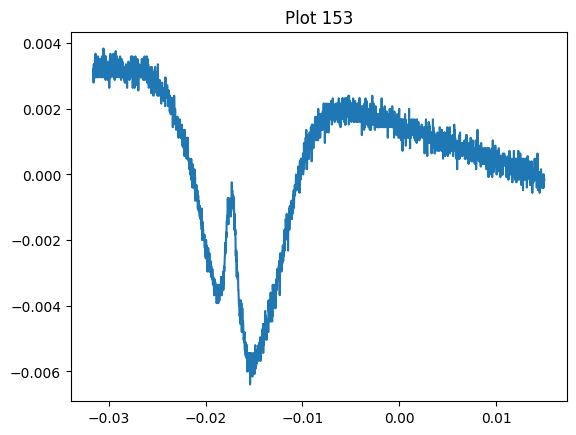

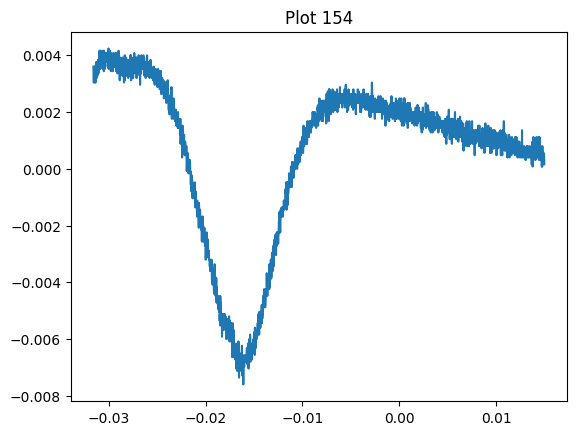

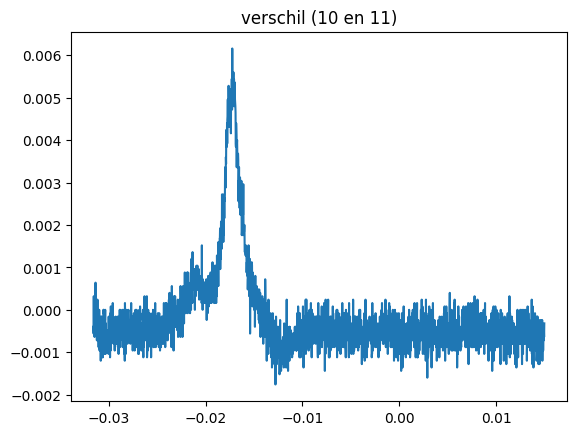

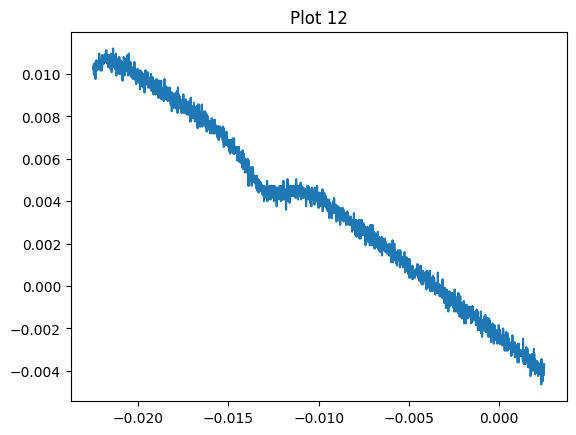

In [151]:
x_1,y_1 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Alle_data_real, gotten on 2026_06_09 and 2026_06_10/TEK0067.CSV')
x_2,y_2 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Alle_data_real, gotten on 2026_06_09 and 2026_06_10/TEK0068.CSV')
x_3,y_3 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Alle_data_real, gotten on 2026_06_09 and 2026_06_10/TEK0150.CSV')
x_red, y_red = subtract(x_1,y_1, x_2, y_2)



plt.plot(x_1,y_1)
plt.title("Plot 153")
plt.show()

plt.plot(x_2,y_2)
plt.title("Plot 154")
plt.show()

plt.plot(x_red, y_red)
plt.title("verschil (10 en 11)")
plt.show()

plt.plot(x_3,y_3)
plt.title("Plot 12")
plt.show()

─────────────────────────────────────────────
Piek 1:
  x0    = -0.01709 ± 0.00002
  gamma = 0.00062 ± 0.00003
  A     = 0.00074 ± 0.00002
Piek 2:
  x0    = -0.01559 ± 0.00001
  gamma = 0.00084 ± 0.00002
  A     = 0.00183 ± 0.00001
Piek 3:
  x0    = -0.01334 ± 0.00002
  gamma = 0.00057 ± 0.00003
  A     = 0.00047 ± 0.00001
Piek 4:
  x0    = 0.00317 ± 0.00002
  gamma = 0.00086 ± 0.00001
  A     = 0.00494 ± 0.00010
Achtergrond B = -0.00041 ± 0.00000
─────────────────────────────────────────────


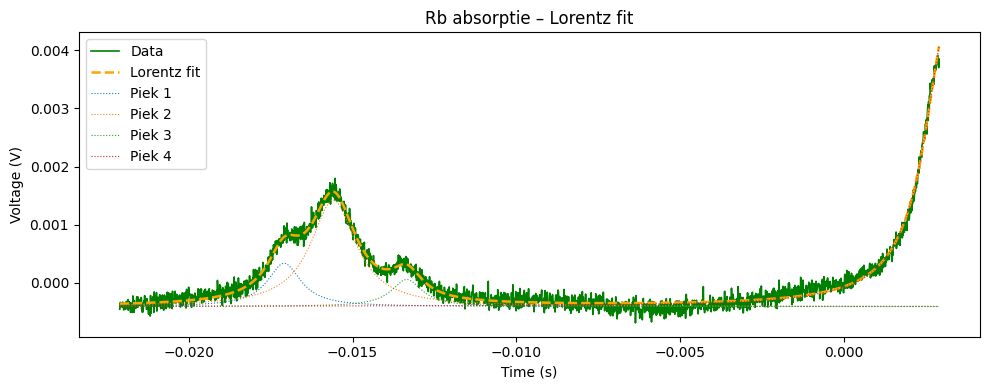

In [150]:


# ── Lorentz bouwstenen ────────────────────────────────────────────────────────

def lorentz(x, x0, gamma, A):
    """Enkele Lorentz-piek (absorptie → negatieve A)."""
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    """
    Som van N Lorentz-pieken + constante achtergrond.
    params = [x0_1, gamma_1, A_1,  x0_2, gamma_2, A_2,  ...,  B]
    """
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr


# ── Gebruik ───────────────────────────────────────────────────────────────────

# Vervang x_subtracted en y_subtracted door jouw arrays
# x_subtracted, y_subtracted = subtract(background_link, real_link)

x0_list  = [-0.017, -0.015, -0.013,  0.005]
A_list   = [0.00047, 0.00182, 0.001, 0.04]

popt, perr = lorentz_fit(
    x_avg_1, y_avg_1,
    x0_list     = x0_list,
    A_list      = A_list,
    gamma_guess = 0.001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit'
)


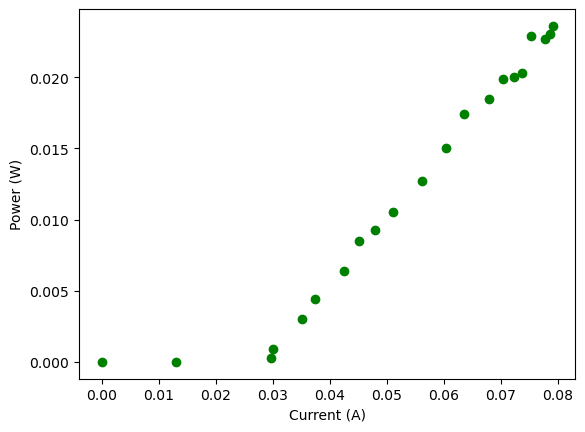

In [17]:
Current = [0.02E-3, 78.63E-3, 51.09E-3, 42.51E-3, 29.72E-3, 56.23E-3, 13.04E-3, 30E-3, 35.09E-3, 37.5E-3, 45.12E-3, 47.87E-3, 63.47E-3, 67.98E-3,
           70.32E-3, 60.46E-3, 75.31E-3, 72.26E-3, 73.76E-3, 77.75E-3, 79.07E-3]

Power = [0, 23E-3, 10.5E-3, 6.4E-3, 0.3E-3, 12.7E-3, 0, 0.9E-3, 3E-3, 4.4E-3, 8.5E-3, 9.3E-3, 17.4E-3, 18.5E-3, 19.9E-3, 15E-3, 22.9E-3 , 20E-3,
         20.3E-3, 22.7E-3, 23.6E-3]

plt.scatter(Current, Power, label='Power vs Current', color='green')
plt.xlabel('Current (A)')
plt.ylabel('Power (W)')
plt.show()